# Label-free auditing of AI-generated image detectors (CVPR 2027 experiments)

**What this notebook does, end to end**
1. Finds the datasets attached under `/kaggle/input` automatically (GenImage-style `*/train|val/ai|nature`, Synthbuster + RAISE, CNNSpot-style `0_real/1_fake`). If nothing is found, it downloads **Tiny-GenImage** from HuggingFace.
2. Normalises every image identically (shorter side -> 256, centre crop, JPEG q95) to remove format/size shortcuts.
3. One cached GPU pass: CLIP ViT-L/14, DINOv2-B, SD-VAE reconstruction error, frequency statistics.
4. Builds the **audited detectors**: CLIP / DINOv2 linear probes, ResNet-50 fine-tuned on one generator (CNNSpot-style), UnivFD (public weights), CNNSpot (if its weights are attached).
5. Builds the **independent real-only auditor**: kNN atypicality vs a real reference set -> conformal p-values -> Cauchy (ACAT) aggregation across auditors.
6. Estimates fake prevalence pi (BBE / Storey) and corrects detector metrics (TPR@1%/5% FPR, AUC, accuracy) with the Jain et al. (2017) identities.
7. Runs all baselines (AC, ATC, DoC, CDTS-entropy regression, MaNo regression, self-score BBE/Storey, single auditors, oracle-pi, 100-label audit), all experiments, and writes tables + figures to `/kaggle/working/results`.

**Before running:** Settings -> Accelerator **GPU T4**, **Internet ON**. Attach GenImage parts (Kaggle mirror) and optionally Synthbuster + RAISE. Run all. Every heavy step is cached in `/kaggle/working/cache`, so a restarted session resumes where it stopped.

In [1]:
import subprocess, sys, importlib
def _pip(pkg, mod=None):
    try:
        importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)
_pip('diffusers'); _pip('datasets'); _pip('transformers'); _pip('tifffile')

In [2]:
# ===================== CONFIG =====================
CFG = dict(
    SEED=0,
    INPUT_ROOT='/kaggle/input',
    WORK='/kaggle/working',
    HF_CACHE='/kaggle/temp/hf',            # Kaggle scratch space (not saved, not your quota)
    USE_HF_FALLBACK=True,                 # download Tiny-GenImage if no GenImage-style data is attached
    HF_TINY='TheKernel01/Tiny-GenImage',
    IMG_SIZE=256, JPEG_Q=95,
    REAL_CROPS_EVAL_ONLY=4,               # crops per real image for eval-only domains (RAISE photos are large)
    REAL_CROP_FRAC=0.8,                   # each crop covers 80% of the frame -> same framing as full-scene fakes
    REAL_PRE_SIZE=1024,                   # downscale large camera photos to ~generator resolution before cropping
    N_FOLDS=5,                            # cross-fitting folds for the union estimator
    POOL_GENIMAGE_REALS=True,             # ref/cal/stream reals from ONE pool (train- and val-split reals mixed)
    DEV_SEEDS=5,                          # streams per setting on the dev generators used to choose the estimator
    LCB_B=20, LCB_Z=1.0,                  # bootstrap size / z for the pessimistic (lower-confidence-bound) union
    # sampling caps (reduce if you run out of time)
    N_FAKE_TRAIN=4000, N_FAKE_SRC_HOLD=500, N_REAL_TRAIN_POOL=12000,
    N_FAKE_EVAL=1000, N_REAL_STREAM=4000,
    N_SHIFT_REAL=1500, N_SHIFT_FAKE=300,
    DEV_GENS=['ADM', 'GLIDE'],            # used only for tuning / fitting regression baselines
    DET_TRAIN_GENS='auto',                # 'auto' = one diffusion (SD1.4 > SD1.5 > Midjourney) + BigGAN, whichever exist
    DET_TRAIN_PREF=[['SD14', 'SD15', 'Midjourney', 'Wukong'], ['BigGAN']],
    N_REAL_EVAL_DOMAIN=3000,              # cap on real images per eval-only domain (e.g. Chameleon has ~15k)
    BATCH=32, WORKERS=4, CHUNK=4096,
    RESNET_EPOCHS=3, RESNET_LR=1e-4, RESNET_BS=64, MIN_RESNET_FAKES=60, MIN_LP_FAKES=30,
    N_DETECTORS=6,                        # 3 families (CLIP-LP, DINO-LP, ResNet50) x 2 training generators; UnivFD/CNNSpot are extras
    KNN_K=10,
    PIS=[0.01, 0.02, 0.05, 0.1, 0.2, 0.5],
    NS=[500, 1000, 2000],
    SEEDS=10,
    BOOT_B=100, CI_LEVEL=0.9, BOOT_SEEDS=3,
    LABEL_BUDGET=100,
    MAIN_PI=0.1, MAIN_N=2000,
    RUN_SHIFT=True, RUN_UNIVFD=True, RUN_CNNSPOT=True,
    UNIVFD_URL='https://github.com/WisconsinAIVision/UniversalFakeDetect/raw/main/pretrained_weights/fc_weights.pth',
)

In [3]:
import os, io, re, json, math, glob, time, random, warnings, urllib.request, zlib
from collections import defaultdict
import numpy as np, pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings('ignore')
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

os.makedirs(CFG['HF_CACHE'], exist_ok=True)
os.environ['HF_HOME'] = CFG['HF_CACHE']
CACHE = os.path.join(CFG['WORK'], 'cache'); RES = os.path.join(CFG['WORK'], 'results'); FIG = os.path.join(RES, 'figures')
for d in (CACHE, RES, FIG): os.makedirs(d, exist_ok=True)

import shutil
def import_previous_cache(max_depth=6):
    """Saves hours: if an earlier run's Output (containing cache/clip.npy) is attached as an Input,
    copy its cached features / detector scores / weights here. Only rows whose preprocessing changed are recomputed."""
    if os.path.exists(os.path.join(CACHE, 'clip.npy')): return
    root = CFG['INPUT_ROOT'].rstrip('/'); d0 = root.count('/')
    for dp, dns, fns in os.walk(root):
        if dp.count('/') - d0 >= max_depth or os.path.basename(dp).lower() in ('ai', 'nature', '0_real', '1_fake', 'raise_1k'):
            dns[:] = []
        if 'clip.npy' in fns and ('manifest.csv' in fns or 'manifest_features.csv' in fns):
            print('Reusing cached features from previous run:', dp)
            for f in fns:
                if f.endswith(('.npy', '.pt', '.pth')) or f == 'manifest_features.csv':
                    dst = os.path.join(CACHE, f)
                elif f == 'manifest.csv':
                    dst = os.path.join(CACHE, 'manifest_prev.csv')
                else: continue
                if not os.path.exists(dst): shutil.copy(os.path.join(dp, f), dst)
            return
import_previous_cache()

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG['SEED'])
def stable_seed(*a): return zlib.crc32(repr(a).encode()) & 0xffffffff   # stable seed (Python hash() is salted)
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEV, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

Reusing cached features from previous run: /kaggle/input/notebooks/kazirifatahmed/cvpr-27-v1/cache
Device: cuda Tesla T4


## 1. Automatic dataset discovery

In [4]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}

def is_img(f): return os.path.splitext(f)[1].lower() in IMG_EXT

def list_images(d):
    out = []
    for dp, _, fs in os.walk(d):
        out += [os.path.join(dp, f) for f in fs if is_img(f)]
    return sorted(out)

GENIMAGE_KW = [(r'sdv4|v1[_-]?4|sd14|sd_?1[._]?4', 'SD14'), (r'sdv5|v1[_-]?5|sd15|sd_?1[._]?5', 'SD15'),
               (r'midjourney', 'Midjourney'), (r'biggan', 'BigGAN'), (r'glide', 'GLIDE'), (r'wukong', 'Wukong'),
               (r'vqdm', 'VQDM'), (r'(^|[^a-z])adm([^a-z]|$)|_adm', 'ADM')]

def canon_genimage(path):
    for p in (os.path.basename(path.rstrip('/')).lower(), path.lower()):
        for pat, name in GENIMAGE_KW:
            if re.search(pat, p): return name
    return os.path.basename(path.rstrip('/'))

SB_MAP = {'dalle2': 'DALLE2', 'dalle3': 'DALLE3', 'firefly': 'Firefly', 'midjourneyv5': 'MJv5', 'midjourney': 'MJv5',
          'stablediffusion13': 'SD1.3', 'stablediffusion14': 'SD1.4', 'stablediffusion2': 'SD2',
          'stablediffusionxl': 'SDXL', 'glide': 'GLIDE'}

def canon_sb(name):
    k = re.sub(r'[^a-z0-9]', '', name.lower())
    return SB_MAP.get(k)

REAL_NAMES = ('0_real', 'real', 'reals', 'nature', 'authentic', 'genuine')
FAKE_NAMES = ('1_fake', 'fake', 'fakes', 'ai', 'aigc', 'synthetic', 'generated')

def dataset_name(dp, root):
    parts = os.path.relpath(dp, root).split(os.sep)
    top = parts[2] if parts[0] in ('datasets', 'notebooks', 'models', 'competitions') and len(parts) > 2 else parts[0]
    return re.sub(r'[\s_\-]*dataset$', '', top.lower()).strip(' _-') or top.lower()

def discover(root):
    found = {'genimage': [], 'synthbuster': [], 'raise': [], 'generic': []}
    for dp, dns, fns in os.walk(root):
        base = os.path.basename(dp).lower()
        sub = {d.lower(): d for d in dns}
        # (a) GenImage layout: <generator>/<train|val>/{ai,nature}  or  <generator>/{ai,nature}
        if 'ai' in sub and 'nature' in sub:
            split = base if base in ('train', 'val') else 'all'
            gdir = os.path.dirname(dp) if split != 'all' else dp
            found['genimage'].append(dict(gen=canon_genimage(gdir), split=split,
                                          ai=os.path.join(dp, sub['ai']), nature=os.path.join(dp, sub['nature'])))
            dns[:] = []; continue
        # (b) Synthbuster layout: one folder per generator (dalle2, dalle3, firefly, ...)
        sb = [(d, canon_sb(d)) for d in dns if canon_sb(d)]
        if len(sb) >= 3:
            for d, g in sb: found['synthbuster'].append(dict(gen=g, path=os.path.join(dp, d)))
            dns[:] = []; continue
        # (c) generic real/fake layout (e.g. Chameleon/test/{0_real,1_fake})
        r = next((sub[k] for k in REAL_NAMES if k in sub), None); f = next((sub[k] for k in FAKE_NAMES if k in sub), None)
        if r and f:
            gname = os.path.basename(os.path.dirname(dp)) if base in ('test', 'val', 'train', 'data', 'images') else os.path.basename(dp)
            found['generic'].append(dict(domain=dataset_name(dp, root), gen=gname,
                                         real=os.path.join(dp, r), fake=os.path.join(dp, f)))
            dns[:] = []; continue
        # (d) RAISE real photos: any folder with images whose path contains "raise"
        if 'raise' in dp.lower() and any(is_img(x) for x in fns[:50]):
            found['raise'].append(dp); dns[:] = []
    found['raise'] = sorted(set(found['raise']))
    for k in ('genimage', 'synthbuster', 'generic'):          # deterministic order -> identical manifest across runs
        found[k] = sorted(found[k], key=lambda e: json.dumps(e, sort_keys=True))
    return found

FOUND = discover(CFG['INPUT_ROOT'])
print('Found:', json.dumps({k: len(v) for k, v in FOUND.items()}))
for e in FOUND['genimage']: print(f"  GenImage   {e['gen']:<11} split={e['split']:<5} {os.path.dirname(e['ai'])}")
for e in FOUND['synthbuster']: print(f"  Synthbuster {e['gen']:<8} {e['path']}")
for e in FOUND['raise']: print(f"  RAISE reals {e}")
for e in FOUND['generic']: print(f"  Real/fake  domain={e['domain']} gen={e['gen']}  real={e['real']}  fake={e['fake']}")
if not FOUND['genimage']: print('WARNING: no GenImage-style folders found (expects <gen>/train|val/ai|nature).')
if FOUND['synthbuster'] and not FOUND['raise']: print('WARNING: Synthbuster found but no RAISE reals -> attach raise1k.')

Found: {"genimage": 14, "synthbuster": 9, "raise": 1, "generic": 1}
  GenImage   BigGAN      split=train /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0419_biggan/train
  GenImage   BigGAN      split=val   /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0419_biggan/val
  GenImage   VQDM        split=train /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0419_vqdm/train
  GenImage   VQDM        split=val   /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0419_vqdm/val
  GenImage   SD15        split=train /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0424_sdv5/train
  GenImage   SD15        split=val   /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0424_sdv5/val
  GenImage   Wukong      split=train /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0424_wukong/train
  GenImage   Wukong      split=val   /kaggle/input/datasets/yangsangtai/tiny-genimage/imagenet_ai_0424_wukong/val
  GenImage   ADM    

## 2. Manifest (one row per image crop) and role assignment
Roles: `det_train` (detector training), `src_hold` (detector's own validation, for ATC/DoC/Platt), `ref` (auditor reference reals), `cal1`/`cal2` (conformal calibration reals), `cal3` (held-out reals for FPR + BBE component), `stream` (mixed into unlabeled streams). All real splits are disjoint.

In [5]:
RNG = np.random.default_rng(CFG['SEED'])
HF_DS = {}

def take(lst, n, rng):
    lst = list(lst)
    if len(lst) <= n: return lst
    idx = rng.choice(len(lst), n, replace=False)
    return [lst[i] for i in sorted(idx)]

def split_roles(n, fracs, rng):
    perm = rng.permutation(n); roles = np.empty(n, dtype=object); start = 0
    names = list(fracs); cuts = np.cumsum([int(round(fracs[k] * n)) for k in names])
    cuts[-1] = n
    for name, c in zip(names, cuts):
        roles[perm[start:c]] = name; start = c
    return roles

rows = []
def add(domain, source, path, label, gen, split, role, crop_id=-1, hf_split=None, hf_idx=-1, group=None):
    rows.append(dict(domain=domain, source=source, path=path, hf_split=hf_split, hf_idx=hf_idx, label=label,
                     gen=gen, split=split, role=role, crop_id=crop_id, variant='clean', group=group or path))

TRAIN_FRACS = dict(det_train=0.5, ref=0.2, cal1=0.1, cal2=0.1, cal3=0.1)
EVAL_FRACS = dict(ref=0.35, cal1=0.1, cal2=0.1, cal3=0.15, stream=0.3)

def dedupe(paths):
    """GenImage repeats the same ImageNet reals across generator folders -> dedupe by file name."""
    seen, out = set(), []
    for p in sorted(paths):
        b = os.path.basename(p)
        if b not in seen: seen.add(b); out.append(p)
    return out

def resolve_train_gens(available):
    if CFG['DET_TRAIN_GENS'] != 'auto': return [g for g in CFG['DET_TRAIN_GENS'] if g in available]
    pick = []
    for group in CFG['DET_TRAIN_PREF']:
        g = next((g for g in group if g in available and g not in CFG['DEV_GENS']), None)
        if g: pick.append(g)
    return pick

def build_train_domain_from_folders(entries, domain='genimage'):
    """Works with train/val splits, val-only, or flat <gen>/{ai,nature}. Without a train split,
    each generator's images are split 50/50 into a training half and an evaluation half."""
    pool = defaultdict(lambda: defaultdict(list))   # gen -> {'train_ai','val_ai','train_nat','val_nat'}
    for e in entries:
        ai, nat = list_images(e['ai']), list_images(e['nature'])
        if e['split'] in ('train', 'val'):
            pool[e['gen']][e['split'] + '_ai'] += ai; pool[e['gen']][e['split'] + '_nat'] += nat
        else:
            pool[e['gen']]['all_ai'] += ai; pool[e['gen']]['all_nat'] += nat
    for g, d in pool.items():
        for kind in ('ai', 'nat'):
            if not d['train_' + kind] and not d['val_' + kind]: d['val_' + kind] = d['all_' + kind]
            if not d['train_' + kind] and d['val_' + kind]:          # carve a training half out of val
                v = list(RNG.permutation(sorted(d['val_' + kind])))
                h = len(v) // 2; d['train_' + kind], d['val_' + kind] = v[:h], v[h:]
    avail = {g for g, d in pool.items() if len(d['train_ai']) >= 50}
    CFG['DET_TRAIN_GENS'] = resolve_train_gens(avail)
    print('Generators:', sorted(pool), '| detector training generators:', CFG['DET_TRAIN_GENS'],
          '| dev (baseline-fitting) generators:', [g for g in CFG['DEV_GENS'] if g in pool])
    train_reals, val_reals = [], []
    for g, d in sorted(pool.items()):
        if g in CFG['DET_TRAIN_GENS']:
            sel = take(d['train_ai'], CFG['N_FAKE_TRAIN'] + CFG['N_FAKE_SRC_HOLD'], RNG)
            n_tr = min(CFG['N_FAKE_TRAIN'], int(len(sel) * 0.85))
            for i, p in enumerate(sel): add(domain, 'file', p, 1, g, 'train', 'det_train' if i < n_tr else 'src_hold')
        for p in take(d['val_ai'], CFG['N_FAKE_EVAL'], RNG): add(domain, 'file', p, 1, g, 'val', 'stream')
        train_reals += d['train_nat']; val_reals += d['val_nat']
    tr = dedupe(train_reals); trn = set(map(os.path.basename, tr))
    va = [p for p in dedupe(val_reals) if os.path.basename(p) not in trn]   # no real image in two splits
    tr = take(tr, CFG['N_REAL_TRAIN_POOL'], RNG)
    for p, r in zip(tr, split_roles(len(tr), TRAIN_FRACS, RNG)): add(domain, 'file', p, 0, 'Real', 'train', r)
    for p in take(va, CFG['N_REAL_STREAM'], RNG): add(domain, 'file', p, 0, 'Real', 'val', 'stream')
    print(f'{domain}: {len(tr)} train-pool reals, {min(len(va), CFG["N_REAL_STREAM"])} stream reals')

def build_train_domain_from_hf():
    from datasets import load_dataset
    print('No GenImage folders found -> downloading', CFG['HF_TINY'])
    if CFG['DET_TRAIN_GENS'] == 'auto': CFG['DET_TRAIN_GENS'] = ['SD14', 'BigGAN']
    for split_name, our in (('train', 'train'), ('validation', 'val')):
        ds = load_dataset(CFG['HF_TINY'], split=split_name, cache_dir=CFG['HF_CACHE'])
        HF_DS[our] = ds
        names = ds.features['generator'].names
        gen_col = np.array(ds['generator'])
        lab_col = np.array(ds['label'])
        for gi, gname in enumerate(names):
            g = canon_genimage(gname) if gname.lower() != 'real' else 'Real'
            idx = np.where(gen_col == gi)[0]
            if g == 'Real' or (len(idx) and lab_col[idx[0]] == 0):
                idx = RNG.permutation(idx)
                if our == 'train':
                    idx = idx[:CFG['N_REAL_TRAIN_POOL']]
                    roles = split_roles(len(idx), TRAIN_FRACS, RNG)
                    for i, r in zip(idx, roles): add('genimage', 'hf', f'hf:{our}:{i}', 0, 'Real', 'train', r, hf_split=our, hf_idx=int(i))
                else:
                    for i in idx[:CFG['N_REAL_STREAM']]: add('genimage', 'hf', f'hf:{our}:{i}', 0, 'Real', 'val', 'stream', hf_split=our, hf_idx=int(i))
            else:
                idx = RNG.permutation(idx)
                if our == 'train':
                    if g not in CFG['DET_TRAIN_GENS']: continue
                    idx = idx[:CFG['N_FAKE_TRAIN'] + CFG['N_FAKE_SRC_HOLD']]
                    for k, i in enumerate(idx):
                        add('genimage', 'hf', f'hf:{our}:{i}', 1, g, 'train',
                            'det_train' if k < CFG['N_FAKE_TRAIN'] else 'src_hold', hf_split=our, hf_idx=int(i))
                else:
                    for i in idx[:CFG['N_FAKE_EVAL']]: add('genimage', 'hf', f'hf:{our}:{i}', 1, g, 'val', 'stream', hf_split=our, hf_idx=int(i))

def build_eval_domain(domain, real_paths, fake_entries, crops):
    reals = take(sorted(set(real_paths)), CFG['N_REAL_EVAL_DOMAIN'], RNG)
    roles = split_roles(len(reals), EVAL_FRACS, RNG)
    for p, r in zip(reals, roles):          # split at IMAGE level, crops inherit the role (no leakage)
        for c in range(crops): add(domain, 'file', p, 0, 'Real', 'test', r, crop_id=c if crops > 1 else -1, group=p)
    for g, paths in fake_entries:
        for p in take(paths, CFG['N_FAKE_EVAL'], RNG): add(domain, 'file', p, 1, g, 'test', 'stream')

if FOUND['genimage']:
    build_train_domain_from_folders(FOUND['genimage'])
elif CFG['USE_HF_FALLBACK']:
    build_train_domain_from_hf()

if FOUND['synthbuster']:
    rp = []
    for d in FOUND['raise']: rp += list_images(d)
    if rp:
        build_eval_domain('synthbuster', rp, [(e['gen'], list_images(e['path'])) for e in FOUND['synthbuster']], CFG['REAL_CROPS_EVAL_ONLY'])
    else:
        print('Synthbuster fakes found but no RAISE reals -> Synthbuster skipped (attach RAISE-1k).')
for e in FOUND['generic']:
    build_eval_domain(e['domain'], list_images(e['real']), [(e['gen'], list_images(e['fake']))], 1)

MAN = pd.DataFrame(rows)
assert len(MAN), 'No data found. Attach GenImage / Synthbuster or enable the HF fallback with Internet ON.'

# real-distribution shift copies (JPEG70 + 2x down/up-sampling) of a subset of the genimage stream
if CFG['RUN_SHIFT'] and (MAN.domain == 'genimage').any():
    s = MAN[(MAN.domain == 'genimage') & (MAN.role == 'stream')]
    parts = [s[s.label == 0].sample(min(CFG['N_SHIFT_REAL'], (s.label == 0).sum()), random_state=0)]
    for g, sg in s[s.label == 1].groupby('gen'):
        parts.append(sg.sample(min(CFG['N_SHIFT_FAKE'], len(sg)), random_state=0))
    sh = pd.concat(parts).copy(); sh['variant'] = 'shift'
    MAN = pd.concat([MAN, sh], ignore_index=True)

MAN = MAN.reset_index(drop=True); MAN['uid'] = np.arange(len(MAN))
if CFG['POOL_GENIMAGE_REALS'] and (MAN.domain == 'genimage').any():
    # GenImage train-split and val-split reals were used for reference/calibration vs stream respectively, which made
    # the 'known real' distribution differ slightly from the stream's reals (8.7% guard false alarms, inflated oracle error).
    # Re-deal those roles from one pool. Role COUNTS, detector-training images and shift-source images are unchanged.
    _shift_src = set(MAN.loc[(MAN.variant == 'shift') & (MAN.label == 0), 'path'])
    _g = np.where((MAN.domain == 'genimage') & (MAN.label == 0) & (MAN.variant == 'clean')
                  & MAN.role.isin(['ref', 'cal1', 'cal2', 'cal3', 'stream']) & ~MAN.path.isin(_shift_src))[0]
    MAN.loc[_g, 'role'] = np.random.default_rng(1).permutation(MAN.loc[_g, 'role'].values)
    print('GenImage reals re-pooled across splits:', MAN.loc[_g].groupby(['role', 'split']).size().to_dict())
def row_key(r, legacy=False):
    c = int(r['crop_id'])
    crop = '-1' if c < 0 else (f'{c}@0.5/0' if legacy else f"{c}@{CFG['REAL_CROP_FRAC']}/{CFG['REAL_PRE_SIZE']}")
    return f"{r['source']}|{r['path']}|{int(r['hf_idx'])}|{crop}|{r['variant']}"
MAN['key'] = [row_key(r) for r in MAN[['source', 'path', 'hf_idx', 'crop_id', 'variant']].to_dict('records')]
MAN.to_csv(os.path.join(CACHE, 'manifest.csv'), index=False)
print(MAN.groupby(['domain', 'variant', 'role', 'label']).size().rename('n').to_string())
DOMAINS = sorted(MAN.domain.unique()); print('Domains:', DOMAINS)

Generators: ['ADM', 'BigGAN', 'GLIDE', 'Midjourney', 'SD15', 'VQDM', 'Wukong'] | detector training generators: ['SD15', 'BigGAN'] | dev (baseline-fitting) generators: ['ADM', 'GLIDE']
genimage: 12000 train-pool reals, 3500 stream reals
GenImage reals re-pooled across splits: {('cal1', 'train'): 881, ('cal1', 'val'): 319, ('cal2', 'train'): 894, ('cal2', 'val'): 306, ('cal3', 'train'): 915, ('cal3', 'val'): 285, ('ref', 'train'): 1820, ('ref', 'val'): 580, ('stream', 'train'): 1490, ('stream', 'val'): 510}
domain       variant  role       label
chameleon    clean    cal1       0         300
                      cal2       0         300
                      cal3       0         450
                      ref        0        1050
                      stream     0         900
                                 1        1000
genimage     clean    cal1       0        1200
                      cal2       0        1200
                      cal3       0        1200
                      det_t

## 3. Identical preprocessing for every image + cached GPU feature pass

In [6]:
S = CFG['IMG_SIZE']

def _crop_box(w, h, crop_id):
    if crop_id < 0: return None
    side = int(min(w, h) * CFG['REAL_CROP_FRAC'])
    pos = [(0, 0), (w - side, 0), (0, h - side), (w - side, h - side), ((w - side) // 2, (h - side) // 2)]
    x, y = pos[crop_id % len(pos)]
    return (x, y, x + side, y + side)

def _jpeg(img, q):
    b = io.BytesIO(); img.save(b, format='JPEG', quality=q); b.seek(0)
    return Image.open(b).convert('RGB')

def load_preprocessed(r):
    if r['source'] == 'hf':
        img = HF_DS[r['hf_split']][int(r['hf_idx'])]['image']
    else:
        try:
            img = Image.open(r['path']); img.load()
        except Exception:                      # e.g. 16-bit RGB TIFF that PIL cannot decode
            import tifffile
            a = tifffile.imread(r['path'])
            if a.dtype != np.uint8: a = (a / max(a.max(), 1) * 255).astype(np.uint8)
            if a.ndim == 2: a = np.stack([a] * 3, -1)
            img = Image.fromarray(a[..., :3])
    img = img.convert('RGB')
    if int(r['crop_id']) >= 0 and min(img.size) > CFG['REAL_PRE_SIZE']:   # camera photos -> generator-like resolution
        sc = CFG['REAL_PRE_SIZE'] / min(img.size)
        img = img.resize((round(img.size[0] * sc), round(img.size[1] * sc)), Image.LANCZOS)
    box = _crop_box(*img.size, int(r['crop_id']))
    if box: img = img.crop(box)
    w, h = img.size; sc = S / min(w, h)
    img = img.resize((max(S, round(w * sc)), max(S, round(h * sc))), Image.BICUBIC)
    w, h = img.size; l, t = (w - S) // 2, (h - S) // 2
    img = img.crop((l, t, l + S, t + S))
    img = _jpeg(img, CFG['JPEG_Q'])
    if r['variant'] == 'shift':
        img = img.resize((S // 2, S // 2), Image.BILINEAR).resize((S, S), Image.BILINEAR)
        img = _jpeg(img, 70)
    return np.asarray(img, dtype=np.uint8)

class ImgDS(Dataset):
    def __init__(self, df):
        self.r = df[['source', 'path', 'hf_split', 'hf_idx', 'crop_id', 'variant', 'label']].to_dict('records')
    def __len__(self): return len(self.r)
    def __getitem__(self, i):
        try: a, ok = load_preprocessed(self.r[i]), 1
        except Exception: a, ok = np.zeros((S, S, 3), np.uint8), 0
        return torch.from_numpy(a).permute(2, 0, 1).contiguous(), ok, int(self.r[i]['label'])

def make_loader(df, shuffle=False, bs=None):
    return DataLoader(ImgDS(df), batch_size=bs or CFG['BATCH'], shuffle=shuffle, num_workers=CFG['WORKERS'],
                      pin_memory=True, drop_last=False, persistent_workers=False)

CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=DEV).view(1, 3, 1, 1)
CLIP_STD = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=DEV).view(1, 3, 1, 1)
IN_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
IN_STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)

def to01(xb): return xb.to(DEV, non_blocking=True).float() / 255.
def prep_224(x, mean, std):
    x = F.interpolate(x, size=(224, 224), mode='bicubic', align_corners=False, antialias=True).clamp(0, 1)
    return (x - mean) / std
def prep_center224(x):
    o = (S - 224) // 2
    return (x[:, :, o:o + 224, o:o + 224] - IN_MEAN) / IN_STD

LAP = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]], device=DEV).view(1, 1, 3, 3)
_yy, _xx = torch.meshgrid(torch.arange(S, device=DEV), torch.arange(S, device=DEV), indexing='ij')
HF_MASK = (torch.sqrt((_yy - S / 2) ** 2 + (_xx - S / 2) ** 2) / (S / 2)) > 0.5

def freq_feats(x):
    g = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
    lap = F.conv2d(g, LAP, padding=1)[:, :, 2:-2, 2:-2]
    e1 = torch.log(lap.pow(2).mean((1, 2, 3)) + 1e-10)
    P = torch.fft.fftshift(torch.fft.fft2(g[:, 0]), dim=(-2, -1)).abs().pow(2)
    e2 = torch.log((P * HF_MASK).sum((1, 2)) / P.sum((1, 2)) + 1e-12)
    return torch.stack([e1, e2], 1)

In [7]:
from transformers import CLIPVisionModelWithProjection, AutoModel
import transformers, diffusers
transformers.logging.set_verbosity_error(); diffusers.logging.set_verbosity_error()   # hides harmless 'UNEXPECTED text_model.*' load report
from diffusers import AutoencoderKL

FEAT_SPECS = {'clip': (768,), 'dino': (768,), 'vae': (), 'freq': (2,), 'ok': ()}

def sync_cache_to_manifest():
    """Re-align every cached per-row array (features, detector scores) to the current manifest by row key.
    Returns a boolean mask of rows whose features are already computed."""
    mf, mp, df_ = (os.path.join(CACHE, f) for f in ('manifest_features.csv', 'manifest_prev.csv', 'done.npy'))
    new_keys = MAN['key'].values
    if os.path.exists(mf):
        old_keys = pd.read_csv(mf, keep_default_na=False)['key'].astype(str).values
    elif os.path.exists(mp):
        o = pd.read_csv(mp, keep_default_na=False)
        old_keys = np.array([row_key(r, legacy=True) for r in o[['source', 'path', 'hf_idx', 'crop_id', 'variant']].to_dict('records')])
    else:
        old_keys = None
    if old_keys is None:
        done = np.zeros(len(MAN), bool)
    elif len(old_keys) == len(new_keys) and (old_keys == new_keys).all():
        done = np.load(df_) if os.path.exists(df_) else np.ones(len(MAN), bool)
    else:
        pos = {k: i for i, k in enumerate(old_keys)}
        src = np.array([pos.get(k, -1) for k in new_keys]); have = src >= 0
        old_done = np.load(df_) if os.path.exists(df_) else np.ones(len(old_keys), bool)
        for f in glob.glob(os.path.join(CACHE, '*.npy')):
            if os.path.basename(f) == 'done.npy': continue
            a = np.load(f)
            if len(a) != len(old_keys): continue
            b = np.full((len(new_keys),) + a.shape[1:], 0 if a.dtype.kind in 'iub' else np.nan, dtype=a.dtype)
            b[have] = a[src[have]]; np.save(f, b)
        done = np.zeros(len(MAN), bool); done[have] = old_done[src[have]]
        print(f'Cache re-aligned: {have.sum()} rows reused, {(~done).sum()} rows need (re)computation')
    np.save(df_, done); MAN[['key']].to_csv(mf, index=False)
    return done

def run_feature_pass():
    done = sync_cache_to_manifest()
    files = {k: os.path.join(CACHE, f'{k}.npy') for k in FEAT_SPECS}
    n = len(MAN)
    if not all(os.path.exists(f) and len(np.load(f, mmap_mode='r')) == n for f in files.values()):
        done[:] = False
        feats = {k: np.full((n,) + sh, 0 if k == 'ok' else np.nan, dtype=np.int64 if k == 'ok' else np.float32)
                 for k, sh in FEAT_SPECS.items()}
    else:
        feats = {k: np.load(f) for k, f in files.items()}
    todo = np.where(~done)[0]
    if len(todo) == 0:
        print('All features cached.'); return feats
    print(f'Computing features for {len(todo)} rows')
    clip = CLIPVisionModelWithProjection.from_pretrained('openai/clip-vit-large-patch14', torch_dtype=torch.float16).to(DEV).eval()
    dino = AutoModel.from_pretrained('facebook/dinov2-base', torch_dtype=torch.float16).to(DEV).eval()
    vae = AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-mse').to(DEV).eval()   # fp32 for consistency with cached rows
    C = CFG['CHUNK']
    for st in range(0, len(todo), C):
        rows_ = todo[st:st + C]; t0 = time.time(); p0 = 0
        for xb, ok, _ in make_loader(MAN.iloc[rows_]):
            x = to01(xb); ix = rows_[p0:p0 + len(xb)]; p0 += len(xb)
            with torch.no_grad():
                feats['clip'][ix] = clip(pixel_values=prep_224(x, CLIP_MEAN, CLIP_STD).half()).image_embeds.float().cpu().numpy()
                feats['dino'][ix] = dino(pixel_values=prep_224(x, IN_MEAN, IN_STD).half()).pooler_output.float().cpu().numpy()
                xin = x * 2 - 1
                rec = vae.decode(vae.encode(xin).latent_dist.mode()).sample
                feats['vae'][ix] = torch.log((rec - xin).pow(2).mean((1, 2, 3)) + 1e-10).cpu().numpy()
                feats['freq'][ix] = freq_feats(x).cpu().numpy()
            feats['ok'][ix] = ok.numpy()
        done[rows_] = True
        for k, f in files.items(): np.save(f, feats[k])
        np.save(os.path.join(CACHE, 'done.npy'), done)
        print(f'rows {st}-{st + len(rows_)} of {len(todo)}: {time.time() - t0:.0f}s')
    del clip, dino, vae; torch.cuda.empty_cache()
    return feats

FEATS = run_feature_pass()
OK = FEATS['ok'].astype(bool)
print('Images failing to load:', (~OK).sum())

All features cached.
Images failing to load: 8


## 4. Audited detectors
Self-trained detectors give a controlled spread of competence (each is trained on ONE generator and evaluated on the others). Public detectors (UnivFD; CNNSpot if its weights are attached) are added when available.

In [8]:
DET = {}       # name -> raw score per manifest row (higher = more fake), NaN where not scored
DET_META = {}  # name -> dict(train_gen, train_domain)

def l2n(a): return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)
train_dom = 'genimage' if (MAN.domain == 'genimage').any() else None

def mask(**kw):
    m = OK.copy()
    for k, v in kw.items():
        m &= MAN[k].isin(v if isinstance(v, (list, tuple, set)) else [v]).values
    return m

if train_dom:
    for feat_name in ('clip', 'dino'):
        for g in CFG['DET_TRAIN_GENS']:
            fk = mask(domain=train_dom, role='det_train', label=1, gen=g)
            if fk.sum() < CFG['MIN_LP_FAKES']:
                print(f'SKIPPED {feat_name.upper()}-LP@{g}: only {fk.sum()} training fakes'); continue
            rk = np.where(mask(domain=train_dom, role='det_train', label=0))[0]
            rk = RNG.choice(rk, min(len(rk), fk.sum()), replace=False)
            X = l2n(np.concatenate([FEATS[feat_name][fk], FEATS[feat_name][rk]]))
            y = np.r_[np.ones(fk.sum()), np.zeros(len(rk))]
            lr = LogisticRegression(C=1.0, max_iter=3000).fit(X, y)
            name = f'{feat_name.upper()}-LP@{g}'
            DET[name] = lr.decision_function(l2n(FEATS[feat_name])).astype(np.float32)
            DET_META[name] = dict(train_gen=g, train_domain=train_dom)
            print('trained', name)

def find_file(pattern, max_depth=4):
    import fnmatch
    root = CFG['INPUT_ROOT'].rstrip('/'); d0 = root.count('/')
    for dp, dns, fns in os.walk(root):
        hit = [f for f in fns if fnmatch.fnmatch(f, pattern)]
        if hit: return os.path.join(dp, hit[0])
        if dp.count('/') - d0 >= max_depth or os.path.basename(dp).lower() in ('ai', 'nature', 'train', 'val'):
            dns[:] = []
    return None

if CFG['RUN_UNIVFD']:
    p = find_file('fc_weights.pth')
    if p is None:
        p = os.path.join(CACHE, 'univfd_fc_weights.pth')
        if not os.path.exists(p):
            try: urllib.request.urlretrieve(CFG['UNIVFD_URL'], p)
            except Exception as e: print('UnivFD weights not downloadable:', e); p = None
    if p:
        try:
            sd = torch.load(p, map_location='cpu')
            sd = {k.split('.')[-1]: v for k, v in sd.items()}
            W, b = sd['weight'].float().numpy(), sd['bias'].float().numpy()
            DET['UnivFD'] = (FEATS['clip'].astype(np.float32) @ W.T + b).ravel().astype(np.float32)
            DET_META['UnivFD'] = dict(train_gen='ProGAN', train_domain=None)
            print('UnivFD loaded from', p)
        except Exception as e:
            print('UnivFD load failed:', e)

trained CLIP-LP@SD15
trained CLIP-LP@BigGAN
trained DINO-LP@SD15
trained DINO-LP@BigGAN
UnivFD loaded from /kaggle/working/cache/univfd_fc_weights.pth


In [9]:
import torchvision

def gpu_aug(x):
    B = x.shape[0]; out = torch.empty(B, 3, 224, 224, device=x.device)
    for i in range(B):
        t, l = np.random.randint(0, S - 224 + 1, 2)
        xi = x[i, :, t:t + 224, l:l + 224]
        out[i] = xi.flip(-1) if np.random.rand() < 0.5 else xi
    return (out - IN_MEAN) / IN_STD

def train_resnet(g):
    ck = os.path.join(CACHE, f'resnet50_{g}.pt')
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Linear(2048, 1); m = m.to(DEV)
    if os.path.exists(ck):
        m.load_state_dict(torch.load(ck, map_location=DEV)); return m.eval()
    fk = MAN[mask(domain=train_dom, role='det_train', label=1, gen=g)]
    rk = MAN[mask(domain=train_dom, role='det_train', label=0)]
    rk = rk.sample(min(len(rk), len(fk)), random_state=0)
    df = pd.concat([fk, rk])
    opt = torch.optim.AdamW(m.parameters(), lr=CFG['RESNET_LR'], weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler()
    for ep in range(CFG['RESNET_EPOCHS']):
        m.train(); tot, n = 0., 0
        for xb, ok, yb in make_loader(df, shuffle=True, bs=CFG['RESNET_BS']):
            keep = ok.bool()
            if keep.sum() == 0: continue
            x = gpu_aug(to01(xb[keep])); y = yb[keep].float().to(DEV)
            with torch.cuda.amp.autocast():
                loss = F.binary_cross_entropy_with_logits(m(x).squeeze(1), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); n += len(y)
        print(f'ResNet50@{g} epoch {ep}: loss {tot / max(n, 1):.4f}')
    torch.save(m.state_dict(), ck)
    return m.eval()

def score_torch_models(models):
    """Scores every non-training row; reuses cached scores and only scores rows that are missing."""
    if not models: return
    for k in models:
        f = os.path.join(CACHE, f'det_{k}.npy')
        v = np.load(f) if os.path.exists(f) else None
        DET[k] = v if (v is not None and len(v) == len(MAN)) else np.full(len(MAN), np.nan, np.float32)
    need = MAN.role.values != 'det_train'
    idx = np.where(need & np.any([~np.isfinite(DET[k]) for k in models], axis=0))[0]
    if len(idx) == 0: return
    print(f'Scoring {len(idx)} rows with {list(models)}')
    pos = 0
    for xb, ok, _ in make_loader(MAN.iloc[idx], bs=64):
        x = prep_center224(to01(xb)); ix = idx[pos:pos + len(xb)]; pos += len(xb)
        with torch.no_grad(), torch.cuda.amp.autocast(enabled=DEV.type == 'cuda'):
            for k, m in models.items():
                DET[k][ix] = m(x).float().squeeze(1).cpu().numpy()
    for k in models: np.save(os.path.join(CACHE, f'det_{k}.npy'), DET[k])

def train_mlp_fallback(g):
    """Non-linear detector on frozen CLIP+DINOv2 features; used only if a ResNet-50 cannot be trained."""
    from sklearn.neural_network import MLPClassifier
    fk = mask(domain=train_dom, role='det_train', label=1, gen=g)
    rk = np.where(mask(domain=train_dom, role='det_train', label=0))[0]
    rk = RNG.choice(rk, min(len(rk), fk.sum()), replace=False)
    Z = np.concatenate([l2n(FEATS['clip']), l2n(FEATS['dino'])], 1)
    X = np.concatenate([Z[fk], Z[rk]]); y = np.r_[np.ones(fk.sum()), np.zeros(len(rk))]
    mlp = MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-3, max_iter=300, early_stopping=True, random_state=0).fit(X, y)
    p = np.clip(mlp.predict_proba(Z)[:, 1], 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).astype(np.float32)

torch_models = {}
if train_dom:
    for g in CFG['DET_TRAIN_GENS']:
        n_f = int(mask(domain=train_dom, role='det_train', label=1, gen=g).sum())
        if DEV.type == 'cuda' and n_f >= CFG['MIN_RESNET_FAKES']:
            torch_models[f'ResNet50@{g}'] = train_resnet(g)
            DET_META[f'ResNet50@{g}'] = dict(train_gen=g, train_domain=train_dom)
        elif n_f >= CFG['MIN_LP_FAKES']:
            why = 'no GPU' if DEV.type != 'cuda' else f'only {n_f} training fakes (< MIN_RESNET_FAKES)'
            print(f'ResNet50@{g} not trained ({why}) -> using MLP@{g} on CLIP+DINOv2 features instead')
            DET[f'MLP@{g}'] = train_mlp_fallback(g); DET_META[f'MLP@{g}'] = dict(train_gen=g, train_domain=train_dom)
        else:
            print(f'SKIPPED ResNet50@{g}: only {n_f} training fakes')
if CFG['RUN_CNNSPOT']:
    p = find_file('blur_jpg_prob*.pth')
    if p:
        m = torchvision.models.resnet50(); m.fc = nn.Linear(2048, 1)
        st = torch.load(p, map_location='cpu'); m.load_state_dict(st.get('model', st))
        torch_models['CNNSpot'] = m.to(DEV).eval(); DET_META['CNNSpot'] = dict(train_gen='ProGAN', train_domain=None)
        print('CNNSpot weights:', p)
    else:
        print('CNNSpot weights not attached (search pattern blur_jpg_prob*.pth) -> skipped')
score_torch_models(torch_models)
del torch_models; torch.cuda.empty_cache()
# ---- detector summary: every audited detector, its training data and its real competence spread ----
def detector_summary():
    rows_ = []
    for k in DET:
        m = DET_META[k]
        aucs = []
        for d in DOMAINS:
            rr = mask(domain=d, role='stream', label=0, variant='clean')
            for g in sorted(MAN.loc[mask(domain=d, role='stream', label=1, variant='clean'), 'gen'].unique()):
                if d == m['train_domain'] and g == m['train_gen']: continue
                ff = mask(domain=d, role='stream', label=1, gen=g, variant='clean')
                sc = np.r_[DET[k][ff], DET[k][rr]]
                if np.isfinite(sc).all() and ff.sum() and rr.sum():
                    aucs.append(roc_auc_score(np.r_[np.ones(ff.sum()), np.zeros(rr.sum())], sc))
        rows_.append(dict(detector=k, trained_on=m['train_gen'], n_unseen_gens=len(aucs),
                          min_AUC=np.min(aucs) if aucs else np.nan, mean_AUC=np.mean(aucs) if aucs else np.nan,
                          max_AUC=np.max(aucs) if aucs else np.nan))
    t = pd.DataFrame(rows_); t.to_csv(os.path.join(RES, 'table_detectors.csv'), index=False); return t

print(f'\n{len(DET)} audited detectors (target {CFG["N_DETECTORS"]}):')
print(detector_summary().round(3).to_string(index=False))
if len(DET) < CFG['N_DETECTORS']:
    print(f'WARNING: only {len(DET)} detectors. See the SKIPPED / "not trained" lines above for the reason.')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s]


CNNSpot weights not attached (search pattern blur_jpg_prob*.pth) -> skipped

7 audited detectors (target 6):
       detector trained_on  n_unseen_gens  min_AUC  mean_AUC  max_AUC
   CLIP-LP@SD15       SD15             16    0.661     0.827    0.978
 CLIP-LP@BigGAN     BigGAN             16    0.353     0.622    0.982
   DINO-LP@SD15       SD15             16    0.491     0.686    0.874
 DINO-LP@BigGAN     BigGAN             16    0.370     0.627    0.954
         UnivFD     ProGAN             17    0.383     0.670    0.983
  ResNet50@SD15       SD15             16    0.464     0.708    0.969
ResNet50@BigGAN     BigGAN             16    0.254     0.473    0.951


## 5. Independent real-only auditors -> directional conformal p-values
Five frozen statistics, each fitted on real images only: CLIP-kNN and DINOv2-kNN atypicality (mean cosine distance to the k nearest **reference reals**), SD-VAE reconstruction error, Laplacian energy and high-frequency spectral ratio.
Each statistic gives **two** auditors: `_hi` flags images that are unusually atypical/large, `_lo` flags images that are unusually *typical*/small (generated images are often smoother and more mode-like than real photos, which the pilot run showed: VAE/frequency AUCs < 0.5).
Conformal p-values use `cal1` reals. `cal2` calibrates the legacy ACAT combination (ablation). `cal3` is the known real component for prevalence estimation.

In [10]:
EMB_FEATS = {'clip': FEATS['clip'], 'dino': FEATS['dino']}
SCALAR_FEATS = {'vae': FEATS['vae'].reshape(-1), 'lap': FEATS['freq'][:, 0], 'hf': FEATS['freq'][:, 1]}
BASE_AUD = list(EMB_FEATS) + list(SCALAR_FEATS)
DIR_AUD = [f'{b}_{t}' for b in BASE_AUD for t in ('hi', 'lo')]       # 10 directional auditors

def knn_atypicality(ref, q, k):
    ref = F.normalize(torch.tensor(ref, dtype=torch.float32, device=DEV), dim=1)
    q = F.normalize(torch.tensor(q, dtype=torch.float32, device=DEV), dim=1)
    out = []
    for i in range(0, len(q), 4096):
        out.append((1 - q[i:i + 4096] @ ref.T).topk(k, dim=1, largest=False).values.mean(1).cpu())
    return torch.cat(out).numpy()

def conformal_p(cal_scores, s):
    """P(real score >= s), conformal (valid for exchangeable reals). Small p = suspicious."""
    c = np.sort(cal_scores)
    n_ge = len(c) - np.searchsorted(c, s, side='left')
    return (1 + n_ge) / (len(c) + 1)

def acat(pmat):
    p = np.clip(pmat, 1e-15, 1 - 1e-15)
    return np.tan((0.5 - p) * np.pi).mean(1)

def raw_auditor_stats(ref_idx):
    raw = {b: knn_atypicality(X[ref_idx], X, CFG['KNN_K']) for b, X in EMB_FEATS.items()}
    raw.update({b: v.astype(np.float32) for b, v in SCALAR_FEATS.items()})
    return raw

def directional_pvalues(raw, c1, c2=None):
    P = {}
    for b, v in raw.items():
        v = np.nan_to_num(v, nan=np.nanmedian(v[c1]))
        P[f'{b}_hi'] = conformal_p(v[c1], v); P[f'{b}_lo'] = conformal_p(-v[c1], -v)
    if c2 is not None:   # legacy one-sided ACAT combination (ablation + real-shift guard)
        stat = acat(np.stack([P[f'{b}_hi'] for b in BASE_AUD], 1)); P['acat'] = conformal_p(stat[c2], stat)
    return P

def auditor_pvalues(ref_domain):
    f = os.path.join(CACHE, f'pvals3_{ref_domain}.npz')
    if os.path.exists(f): return dict(np.load(f))
    base = dict(domain=ref_domain, variant='clean')
    ref, c1, c2 = mask(role='ref', **base), mask(role='cal1', **base), mask(role='cal2', **base)
    print(f'[{ref_domain}] ref={ref.sum()} cal1={c1.sum()} cal2={c2.sum()}')
    P = directional_pvalues(raw_auditor_stats(np.where(ref)[0]), c1, c2)
    np.savez(f, **P)
    return P

PVALS = {d: auditor_pvalues(d) for d in DOMAINS if mask(domain=d, role='ref').sum() >= 50}
print('Auditor reference domains:', list(PVALS))

[chameleon] ref=1050 cal1=300 cal2=300
[genimage] ref=2400 cal1=1200 cal2=1200
[synthbuster] ref=1400 cal1=400 cal2=400
Auditor reference domains: ['chameleon', 'genimage', 'synthbuster']


## 6. Pilot / go-no-go: is prevalence identifiable?
Prevalence is identifiable when at least ONE candidate score (a directional auditor or the detector itself) puts fakes away from reals. The union estimator automatically uses the best one, so the go/no-go uses the best candidate per generator.

         domain         gen best_auditor  best_auditor_AUC  aud_acat  det_CLIP-LP@SD15  det_CLIP-LP@BigGAN  det_DINO-LP@SD15  det_DINO-LP@BigGAN  det_UnivFD  det_ResNet50@SD15  det_ResNet50@BigGAN
0     chameleon   Chameleon      clip_hi             0.810     0.634             0.703               0.353             0.734               0.399       0.476              0.762                0.375
1      genimage         ADM       lap_lo             0.686     0.387             0.746               0.951             0.527               0.902       0.918              0.510                0.594
2      genimage      BigGAN       lap_lo             0.974     0.083             0.668               1.000             0.491               0.997       0.983              0.464                1.000
3      genimage       GLIDE       lap_lo             0.959     0.090             0.874               0.982             0.775               0.779       0.859              0.685                0.951
4      genimage

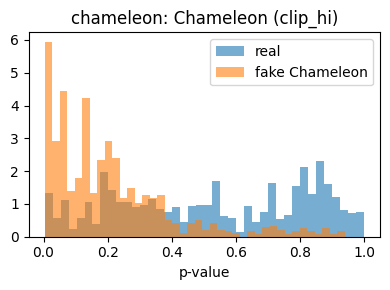

In [11]:
def auditor_auc_table():
    out = []
    for d, P in PVALS.items():
        r = mask(domain=d, role='stream', label=0, variant='clean')
        for g in sorted(MAN.loc[mask(domain=d, role='stream', label=1, variant='clean'), 'gen'].unique()):
            fk = mask(domain=d, role='stream', label=1, gen=g, variant='clean')
            y = np.r_[np.ones(fk.sum()), np.zeros(r.sum())]
            row = dict(domain=d, gen=g)
            for a in DIR_AUD + ['acat']:
                row[f'aud_{a}'] = roc_auc_score(y, -np.r_[P[a][fk], P[a][r]])
            row['best_auditor'] = max(DIR_AUD, key=lambda a: row[f'aud_{a}'])
            row['best_auditor_AUC'] = row[f'aud_{row["best_auditor"]}']
            for det in DET:
                sc = np.r_[DET[det][fk], DET[det][r]]
                row[f'det_{det}'] = roc_auc_score(y, sc) if np.isfinite(sc).all() else np.nan
            out.append(row)
    return pd.DataFrame(out)

PILOT = auditor_auc_table()
PILOT.to_csv(os.path.join(RES, 'pilot_auc_auditors_vs_detectors.csv'), index=False)
show = ['domain', 'gen', 'best_auditor', 'best_auditor_AUC', 'aud_acat'] + [c for c in PILOT if c.startswith('det_')]
print(PILOT[show].round(3).to_string())
for d, q in PILOT.groupby('domain'):
    med = q['best_auditor_AUC'].median()
    verdict = 'GO' if med >= 0.75 else ('BORDERLINE' if med >= 0.65 else 'NO-GO: no auditor separates these fakes; the union will fall back to the detector')
    print(f'[{d}] median best-auditor AUC = {med:.3f} (legacy ACAT {q["aud_acat"].median():.3f}) -> {verdict}')

d0 = list(PVALS)[0]; P = PVALS[d0]
r = mask(domain=d0, role='stream', label=0, variant='clean')
q0 = PILOT[PILOT.domain == d0].head(4)
fig, ax = plt.subplots(1, len(q0), figsize=(4 * len(q0), 3))
for a, (_, row) in zip(np.atleast_1d(ax), q0.iterrows()):
    fk = mask(domain=d0, role='stream', label=1, gen=row.gen, variant='clean'); b = row.best_auditor
    a.hist(P[b][r], bins=40, alpha=.6, density=True, label='real')
    a.hist(P[b][fk], bins=40, alpha=.6, density=True, label=f'fake {row.gen}')
    a.set_title(f'{d0}: {row.gen} ({b})'); a.set_xlabel('p-value'); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, 'pilot_pvalue_hist.png'), dpi=150); plt.show()

## 7. Estimators
* **BBE** (Garg et al., 2021) and **Storey** on any score where the real component is known.
* **Lower-bound property.** For ANY score and threshold set A, P_stream(A) >= (1-pi) P_real(A), so every mixture-proportion estimate is (in population) a LOWER bound on pi. Hence the **maximum over many candidate scores is still a lower bound**, and it automatically uses the least-fooled one.
* **Ours = union-MPE**: candidates = 10 directional real-only auditors + the audited detector's own score; take the max with **K-fold cross-fitting** (choose the score/threshold on K-1 folds of the stream and of the real calibration set, estimate on the held-out fold) to remove the upward selection bias of a plain max.
* **Jain et al. (2017) identities**: with prevalence pi, stream exceedance M(t) and real FPR F(t):
  TPR(t) = (M(t) - (1-pi) F(t)) / pi,  AUC = (P(S_stream > S_real) - (1-pi)/2) / pi.
* **Proposition (used in the paper).** If the auditor's top bin (p >= c) contains real mass q_r and fake mass q_f, then pi_hat = pi (1 - q_f/q_r) and the recall error is exactly
  TPR_hat - TPR = rho/(1-rho) * (TPR - FPR), rho = q_f/q_r.
  (before clipping the estimate to [0, 1]). A self-audit uses rho_self = the detector's own fooling ratio, which grows exactly when TPR falls; that is why self-audits fail silently on the generators that matter. The union uses rho* = min(rho over auditors, rho_self), so its error is never larger than the better of the two (up to finite-sample noise).

In [12]:
def bbe(comp, mix, delta=0.1, gamma=0.01, n_grid=100):
    """Best Bin Estimation. comp: scores of the known component (reals), mix: unlabeled stream.
    Higher score = more real-like. Returns (pi_fake_hat, threshold)."""
    comp = np.sort(np.asarray(comp)); mix = np.sort(np.asarray(mix))
    grid = np.unique(np.quantile(comp, np.linspace(0., 0.99, n_grid)))
    qp = 1 - np.searchsorted(comp, grid, 'left') / len(comp)
    qu = 1 - np.searchsorted(mix, grid, 'left') / len(mix)
    eps = np.sqrt(np.log(4 / delta) / (2 * len(comp))) + np.sqrt(np.log(4 / delta) / (2 * len(mix)))
    ub = np.where(qp > 0, qu / np.maximum(qp, 1e-12) + (1 + gamma) / np.maximum(qp, 1e-12) * eps, np.inf)
    j = int(np.argmin(ub))
    return float(np.clip(1 - qu[j] / qp[j], 0, 1)), grid[j]

def storey(comp, mix, q=0.5):
    lam = np.quantile(comp, q)
    return float(np.clip(1 - np.mean(mix >= lam) / max(np.mean(comp >= lam), 1e-12), 0, 1))

def p_greater(s, r_sorted):
    lo = np.searchsorted(r_sorted, s, 'left'); hi = np.searchsorted(r_sorted, s, 'right')
    return float(np.mean((lo + 0.5 * (hi - lo)) / len(r_sorted)))

def jain(pi_hat, st, ctx):
    """Corrected metrics from prevalence. st: precomputed stream statistics."""
    pi_c = max(pi_hat, 1e-3)
    tpr = lambda m, f: float(np.clip((m - (1 - pi_c) * f) / pi_c, 0, 1))
    auc = float(np.clip((st['psr'] - (1 - pi_c) * 0.5) / pi_c, 0, 1))
    acc = pi_hat * tpr(st['m05'], ctx['f05']) + (1 - pi_hat) * (1 - ctx['f05'])
    return dict(pi=pi_hat, tpr1=tpr(st['m1'], ctx['f1']), tpr5=tpr(st['m5'], ctx['f5']), auc=auc, acc=float(acc))

def conf_from_raw(s, ctx):
    p = 1 / (1 + np.exp(-(ctx['pa'] * s + ctx['pb'])))
    return p, np.maximum(p, 1 - p)

def entropy_signal(s, ctx):
    p, _ = conf_from_raw(s, ctx); p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(np.mean(-(p * np.log(p) + (1 - p) * np.log(1 - p))))

def mano_signal(s, ctx, pnorm=4):
    p, _ = conf_from_raw(s, ctx); q = np.stack([1 - p, p], 1)
    return float((np.mean(np.abs(q) ** pnorm)) ** (1 / pnorm))

def union_mpe(cands, cal_idx, idx, rng, folds=None):
    """cands: {name: score over ALL manifest rows, higher = more real-like}. cal_idx: known-real rows, idx: stream rows.
    Returns (pi_hat, chosen candidate names). folds=1 -> plain max (no cross-fitting)."""
    K = CFG['N_FOLDS'] if folds is None else folds
    if K <= 1:
        best = max(((bbe(v[cal_idx], v[idx])[0], k) for k, v in cands.items()), key=lambda z: z[0])
        return best[0], [best[1]]
    fi = np.array_split(rng.permutation(idx), K); fc = np.array_split(rng.permutation(cal_idx), K)
    ests, picks = [], []
    for j in range(K):
        sS = np.concatenate([fi[i] for i in range(K) if i != j]); sC = np.concatenate([fc[i] for i in range(K) if i != j])
        p_best, t_best, k_best = -1., None, None
        for k, v in cands.items():
            p, t = bbe(v[sC], v[sS])
            if p > p_best: p_best, t_best, k_best = p, t, k
        v = cands[k_best]
        qp = np.mean(v[fc[j]] >= t_best); qu = np.mean(v[fi[j]] >= t_best)
        ests.append(float(np.clip(1 - qu / max(qp, 1e-12), 0, 1))); picks.append(k_best)
    return float(np.mean(ests)), picks

def union_lcb(cands, cal_idx, idx, rng, B=None, z=None):
    """Pessimistic union: for each candidate, BBE estimate minus z * bootstrap s.d.; report the best such lower bound.
    Penalises candidates whose high estimate is just noise (the source of the plain max's upward bias)."""
    B = CFG['LCB_B'] if B is None else B; z = CFG['LCB_Z'] if z is None else z
    full = {k: bbe(v[cal_idx], v[idx])[0] for k, v in cands.items()}
    boots = {k: [] for k in cands}
    for _ in range(B):
        bi = rng.choice(idx, len(idx)); bc = rng.choice(cal_idx, len(cal_idx))
        for k, v in cands.items(): boots[k].append(bbe(v[bc], v[bi])[0])
    return float(max(max(full[k] - z * np.std(boots[k]), 0.) for k in cands))

def union_estimate(kind, cands, cal_idx, idx, rng, lcb_B=None):
    if kind == 'max': return union_mpe(cands, cal_idx, idx, rng, folds=1)[0]
    if kind == 'xfit': return union_mpe(cands, cal_idx, idx, rng)[0]
    if kind == 'lcb': return union_lcb(cands, cal_idx, idx, rng, B=lcb_B)
    raise ValueError(kind)

def union_storey(cands, cal_idx, idx):
    return max(storey(v[cal_idx], v[idx]) for v in cands.values())

NAN5 = dict(pi=np.nan, tpr1=np.nan, tpr5=np.nan, auc=np.nan, acc=np.nan)

## 8. Per-(reference domain, detector) context: thresholds, Platt calibration, source set for ATC/DoC

In [13]:
def build_ctx(ref_domain, det):
    s = DET[det]
    cal3 = mask(domain=ref_domain, role='cal3', label=0, variant='clean') & np.isfinite(s)
    cal2 = mask(domain=ref_domain, role='cal2', label=0, variant='clean') & np.isfinite(s)
    if cal3.sum() < 30: return None
    R = np.sort(s[cal3])
    t1, t5 = np.quantile(R, 0.99), np.quantile(R, 0.95)
    # labelled source set = detector's own held-out validation (src_hold) or, for public detectors, the dev generators
    meta = DET_META[det]; sdom = meta['train_domain'] or train_dom or ref_domain
    src_f = mask(domain=sdom, role='src_hold', label=1, gen=meta['train_gen']) & np.isfinite(s)
    if src_f.sum() < 50:
        src_f = mask(domain=sdom, role='stream', label=1, gen=CFG['DEV_GENS'], variant='clean') & np.isfinite(s)
    src_r = mask(domain=sdom, role='cal3', label=0, variant='clean') & np.isfinite(s)
    ctx = dict(R=R, t1=t1, t5=t5, f1=float(np.mean(R > t1)), f5=float(np.mean(R > t5)), cal2_sorted=np.sort(s[cal2]))
    if src_f.sum() >= 20 and src_r.sum() >= 20:
        xs = np.r_[s[src_f], s[src_r]]; ys = np.r_[np.ones(src_f.sum()), np.zeros(src_r.sum())]
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(xs.reshape(-1, 1), ys)
        ctx['pa'], ctx['pb'] = float(lr.coef_[0, 0]), float(lr.intercept_[0])
        p, conf = conf_from_raw(xs, ctx); pred = p > 0.5
        ctx['src_acc'] = float(np.mean(pred == ys)); ctx['src_conf'] = float(conf.mean())
        ctx['atc_tau'] = float(np.quantile(conf, 1 - ctx['src_acc']))
    else:
        ctx['pa'], ctx['pb'] = 1.0, 0.0
    ctx['t05'] = -ctx['pb'] / ctx['pa'] if ctx['pa'] != 0 else 0.
    ctx['f05'] = float(np.mean(R > ctx['t05']))
    return ctx

CAL3 = {d: mask(domain=d, role='cal3', label=0, variant='clean') for d in PVALS}
CTX = {(d, det): build_ctx(d, det) for d in PVALS for det in DET}
CTX = {k: v for k, v in CTX.items() if v is not None}
print('contexts:', len(CTX))

contexts: 21


## 9. One unlabeled stream -> every method's estimate

In [14]:
OURS = 'Ours (union + detector)'
OURS_AUD = 'Ours (union, auditors only)'
VARIANTS = {'Union+det: plain max': 'max', 'Union+det: 5-fold cross-fit': 'xfit', 'Union+det: LCB': 'lcb'}
CHOSEN = {'kind': 'xfit'}      # overwritten by the dev-generator selection (Section 10b)
# name -> (candidate auditors, include detector score?, estimator kind; 'chosen' = the dev-selected kind)
AUD_METHODS = {OURS: (DIR_AUD, True, 'chosen'), OURS_AUD: (DIR_AUD, False, 'chosen'),
               **{v: (DIR_AUD, True, k) for v, k in VARIANTS.items()},
               'Union, upper tails only': ([a for a in DIR_AUD if a.endswith('_hi')], False, 'chosen'),
               'Aud CLIP (both tails)': (['clip_hi', 'clip_lo'], False, 'chosen'),
               'Aud DINOv2 (both tails)': (['dino_hi', 'dino_lo'], False, 'chosen'),
               'Aud VAE (both tails)': (['vae_hi', 'vae_lo'], False, 'chosen'),
               'Aud Freq (both tails)': (['lap_hi', 'lap_lo', 'hf_hi', 'hf_lo'], False, 'chosen'),
               'ACAT agg (BBE)': (['acat'], False, 'max')}
CAL3_IDX = {}
REG_MODELS = {}   # (det, signal) -> {metric: (slope, intercept)}

def stream_stats(s, ctx):
    return dict(m1=float(np.mean(s > ctx['t1'])), m5=float(np.mean(s > ctx['t5'])),
                m05=float(np.mean(s > ctx['t05'])), psr=p_greater(s, ctx['R']))

def truths(s, y, ctx, pi):
    f = s[y == 1]
    return dict(pi=pi, tpr1=float(np.mean(f > ctx['t1'])), tpr5=float(np.mean(f > ctx['t5'])),
                auc=float(roc_auc_score(y, s)) if 0 < y.sum() < len(y) else np.nan,
                acc=float(np.mean((s > ctx['t05']) == y)))

def estimate_all(idx, y, ref_domain, det, rng, methods='all'):
    ctx = CTX[(ref_domain, det)]; s = DET[det][idx]; P = PVALS[ref_domain]
    st = stream_stats(s, ctx); out = {}
    cal_idx = CAL3_IDX.setdefault(ref_domain, np.where(CAL3[ref_domain])[0])
    cal_idx = cal_idx[np.isfinite(DET[det][cal_idx])]
    neg_det = -DET[det]
    for name, (members, use_det, kind) in AUD_METHODS.items():
        if methods != 'all' and name not in methods: continue
        cands = {a: P[a] for a in members}
        if use_det: cands['detector'] = neg_det
        k = CHOSEN['kind'] if kind == 'chosen' else kind
        if name in VARIANTS and k == CHOSEN['kind'] and OURS in out:     # identical to Ours -> reuse, saves time
            out[name] = out[OURS]; continue
        out[name] = jain(union_estimate(k, cands, cal_idx, idx, rng), st, ctx)
    if methods == 'all' or 'Union Storey (auditors)' in methods:
        out['Union Storey (auditors)'] = jain(union_storey({a: P[a] for a in DIR_AUD}, cal_idx, idx), st, ctx)
    if methods == 'all' or 'Self-score BBE' in methods:
        out['Self-score BBE'] = jain(bbe(-ctx['R'], -s)[0], st, ctx)
    if methods == 'all' or 'Self-score Storey' in methods:
        out['Self-score Storey'] = jain(storey(-ctx['R'], -s), st, ctx)
    if methods == 'all' or 'Oracle-pi' in methods:
        out['Oracle-pi'] = jain(float(np.mean(y)), st, ctx)
    if methods != 'all': return out, st
    # accuracy-only estimators (need a labelled source set)
    p, conf = conf_from_raw(s, ctx)
    for nm in ('AC', 'ATC', 'DoC'): out[nm] = dict(NAN5)
    out['AC']['acc'] = float(conf.mean())
    if 'atc_tau' in ctx:
        out['ATC']['acc'] = float(np.mean(conf > ctx['atc_tau']))
        out['DoC']['acc'] = float(ctx['src_acc'] - (ctx['src_conf'] - conf.mean()))
    # regression baselines (CDTS-style entropy monitor, MaNo), fitted on dev generators
    for sig_name, fn in (('Entropy-reg (CDTS)', entropy_signal), ('MaNo-reg', mano_signal)):
        coefs = REG_MODELS.get((det, sig_name)); e = dict(NAN5)
        if coefs:
            v = fn(s, ctx)
            for mt, (a, b) in coefs.items(): e[mt] = float(np.clip(a * v + b, 0, 1))
        out[sig_name] = e
    # small labelled audit
    k = min(CFG['LABEL_BUDGET'], len(idx)); li = rng.choice(len(idx), k, replace=False)
    yl, sl = y[li], s[li]; e = dict(NAN5); e['pi'] = float(yl.mean())
    if yl.sum() > 0:
        e['tpr1'] = float(np.mean(sl[yl == 1] > ctx['t1'])); e['tpr5'] = float(np.mean(sl[yl == 1] > ctx['t5']))
    if 0 < yl.sum() < k: e['auc'] = float(roc_auc_score(yl, sl))
    e['acc'] = float(np.mean((sl > ctx['t05']) == yl))
    out[f"Labelled audit ({CFG['LABEL_BUDGET']})"] = e
    return out, st

## 10. Stream sampler, eval generators, regression-baseline fitting on dev generators

In [15]:
def pools(stream_domain, variant='clean'):
    r = np.where(mask(domain=stream_domain, role='stream', label=0, variant=variant))[0]
    fk = {g: np.where(mask(domain=stream_domain, role='stream', label=1, gen=g, variant=variant))[0]
          for g in sorted(MAN.loc[mask(domain=stream_domain, role='stream', label=1, variant=variant), 'gen'].unique())}
    return r, fk

def sample_stream(rpool, fpools, pi, n, rng):
    nf = max(1, int(round(pi * n))); nr = n - nf
    if isinstance(fpools, dict):  # mixed generators, equal shares
        gs = list(fpools); share = np.array_split(np.arange(nf), len(gs))
        if any(len(sh) > len(fpools[g]) for g, sh in zip(gs, share)) or nr > len(rpool): return None
        f = np.concatenate([rng.choice(fpools[g], len(sh), replace=False) for g, sh in zip(gs, share)])
    else:
        if nf > len(fpools) or nr > len(rpool): return None
        f = rng.choice(fpools, nf, replace=False)
    idx = np.r_[f, rng.choice(rpool, nr, replace=False)]
    y = np.r_[np.ones(nf), np.zeros(nr)].astype(int)
    return idx, y

def eval_gens(det, stream_domain, all_gens):
    meta = DET_META[det]; out = []
    for g in all_gens:
        if stream_domain == train_dom and g in CFG['DEV_GENS']: continue
        if stream_domain == meta['train_domain'] and g == meta['train_gen']: continue
        out.append(g)
    return out

def fit_regressions():
    if train_dom is None or train_dom not in PVALS: return
    rpool, fpools = pools(train_dom)
    dev = [g for g in CFG['DEV_GENS'] if g in fpools]
    if not dev: print('No dev generators -> regression baselines skipped'); return
    rng = np.random.default_rng(123)
    for det in DET:
        if (train_dom, det) not in CTX: continue
        ctx = CTX[(train_dom, det)]; rec = defaultdict(list)
        for g in dev:
            for pi in CFG['PIS']:
                for n in CFG['NS']:
                    for _ in range(5):
                        smp = sample_stream(rpool, fpools[g], pi, n, rng)
                        if smp is None: continue
                        idx, y = smp; s = DET[det][idx]
                        if not np.isfinite(s).all(): continue
                        tr = truths(s, y, ctx, pi)
                        rec['ent'].append(entropy_signal(s, ctx)); rec['mano'].append(mano_signal(s, ctx))
                        for mt in ('tpr1', 'tpr5', 'auc', 'acc'): rec[mt].append(tr[mt])
        if len(rec['ent']) < 5: continue
        for sig, key in (('Entropy-reg (CDTS)', 'ent'), ('MaNo-reg', 'mano')):
            x = np.array(rec[key]); REG_MODELS[(det, sig)] = {}
            for mt in ('tpr1', 'tpr5', 'auc', 'acc'):
                yv = np.array(rec[mt]); ok_ = np.isfinite(yv)
                REG_MODELS[(det, sig)][mt] = tuple(np.polyfit(x[ok_], yv[ok_], 1))
fit_regressions(); print('regression baselines fitted:', len(REG_MODELS))

regression baselines fitted: 14


## 10b. Choose the union's selection rule on the DEV generators only (never on evaluation generators)
Plain max: slight upward bias at low prevalence. Cross-fitting: unbiased selection but noisy, downward bias at higher prevalence.
LCB: penalises candidates whose estimate is mostly noise. The rule with the lowest recall@5%FPR error on the dev
generators (ADM, GLIDE of the training domain) becomes 'Ours' for every evaluation table.

In [16]:
def select_estimator():
    f = os.path.join(RES, 'table_dev_estimator_selection.csv')
    dom = train_dom
    if dom is None or dom not in PVALS: print('no dev domain -> keeping', CHOSEN); return
    rpool, fpools = pools(dom); dev = [g for g in CFG['DEV_GENS'] if g in fpools]
    if not dev: print('no dev generators -> keeping', CHOSEN); return
    recs = []
    for det in DET:
        if (dom, det) not in CTX: continue
        ctx = CTX[(dom, det)]
        for g in dev:
            for pi in CFG['PIS']:
                for seed in range(CFG['DEV_SEEDS']):
                    rng = np.random.default_rng(stable_seed('dev', det, g, pi, seed))
                    smp = sample_stream(rpool, fpools[g], pi, main_n_for_pool(rpool, len(fpools[g]), pi), rng)
                    if smp is None: continue
                    idx, y = smp; s_ = DET[det][idx]
                    if not np.isfinite(s_).all(): continue
                    tr = truths(s_, y, ctx, float(y.mean()))
                    est, _ = estimate_all(idx, y, dom, det, rng, methods=list(VARIANTS) + ['Self-score BBE'])
                    for m, e in est.items():
                        recs.append((det, g, pi, m, abs(e['pi'] - tr['pi']), abs(e['tpr5'] - tr['tpr5'])))
    t = pd.DataFrame(recs, columns=['detector', 'gen', 'pi', 'method', 'err_pi', 'err_tpr5'])
    summ = t.groupby('method')[['err_pi', 'err_tpr5']].mean().sort_values('err_tpr5')
    summ.to_csv(f); print(summ.round(4).to_string())
    best = summ.drop(index='Self-score BBE', errors='ignore').index[0]
    CHOSEN.update(kind=VARIANTS[best], name=best, done=True)
    print(f'==> Ours uses: {best}  (chosen on dev generators {dev}; evaluation generators were not used)')

def main_n_for_pool(rpool, n_fake, pi):
    ok_ns = [n for n in CFG['NS'] if round(pi * n) <= n_fake and n - round(pi * n) <= len(rpool)]
    return CFG['MAIN_N'] if CFG['MAIN_N'] in ok_ns else (max(ok_ns) if ok_ns else min(CFG['NS']))

select_estimator()

                             err_pi  err_tpr5
method                                       
Union+det: LCB               0.0331    0.1409
Union+det: plain max         0.0295    0.1431
Union+det: 5-fold cross-fit  0.0353    0.1627
Self-score BBE               0.0557    0.1739
==> Ours uses: Union+det: LCB  (chosen on dev generators ['ADM', 'GLIDE']; evaluation generators were not used)


## 11. MAIN EXPERIMENT: single-generator streams, prevalence x stream-size sweep

In [17]:
def main_experiment():
    f = os.path.join(RES, f'trials_main_{stable_seed(sorted(DET), sorted(AUD_METHODS), CHOSEN["kind"], CFG["POOL_GENIMAGE_REALS"], "v5"):08x}.parquet')
    if os.path.exists(f): return pd.read_parquet(f)
    recs = []; t0 = time.time()
    for dom in PVALS:
        rpool, fpools = pools(dom)
        for det in DET:
            if (dom, det) not in CTX: continue
            ctx = CTX[(dom, det)]
            for g in eval_gens(det, dom, list(fpools)):
                for pi in CFG['PIS']:
                    for n in CFG['NS']:
                        for seed in range(CFG['SEEDS']):
                            rng = np.random.default_rng(stable_seed(dom, det, g, pi, n, seed))
                            smp = sample_stream(rpool, fpools[g], pi, n, rng)
                            if smp is None: continue
                            idx, y = smp; s = DET[det][idx]
                            if not np.isfinite(s).all(): continue
                            tr = truths(s, y, ctx, float(y.mean()))
                            est, _ = estimate_all(idx, y, dom, det, rng)
                            for m, e in est.items():
                                for mt in ('pi', 'tpr1', 'tpr5', 'auc', 'acc'):
                                    recs.append((dom, dom, det, g, pi, n, seed, m, mt, e[mt], tr[mt]))
        print(f'{dom} done, {len(recs)} records, {time.time() - t0:.0f}s')
    df = pd.DataFrame(recs, columns=['stream_domain', 'ref_domain', 'detector', 'gen', 'pi', 'n', 'seed',
                                     'method', 'metric', 'est', 'true'])
    df['abs_err'] = (df.est - df.true).abs(); df['signed_err'] = df.est - df.true
    df.to_parquet(f); return df

TRIALS = main_experiment()
print(TRIALS.shape)

chameleon done, 66150 records, 177s
genimage done, 583800 records, 1611s
synthbuster done, 1443750 records, 3769s
(1443750, 13)


## 12. Results: main tables

In [18]:
METHOD_GROUPS = {
    'uses detector scores': ['AC', 'ATC', 'DoC', 'Entropy-reg (CDTS)', 'MaNo-reg', 'Self-score Storey', 'Self-score BBE'],
    'independent auditors (ablations)': ['ACAT agg (BBE)', 'Aud CLIP (both tails)', 'Aud DINOv2 (both tails)', 'Aud VAE (both tails)',
                                         'Aud Freq (both tails)', 'Union, upper tails only', 'Union Storey (auditors)', OURS_AUD],
    'union selection rule (ablation)': list(VARIANTS),
    'ours': [OURS],
    'reference': ['Oracle-pi', f"Labelled audit ({CFG['LABEL_BUDGET']})"]}
ORDER = [m for g in METHOD_GROUPS.values() for m in g]

def main_n_for(df, dom, pi=None):
    """Largest stream size that actually has trials for this domain at prevalence `pi` (default MAIN_PI).
    Eval-only domains (Synthbuster, Chameleon) have fewer stream reals, so their largest n can be smaller."""
    pi = CFG['MAIN_PI'] if pi is None else pi
    d = df[df.stream_domain == dom]
    ns = sorted(d[np.isclose(d.pi, pi)].n.unique()) or sorted(d.n.unique())
    return CFG['MAIN_N'] if CFG['MAIN_N'] in ns else ns[-1]

METRICS = ['pi', 'tpr1', 'tpr5', 'auc', 'acc']

def main_table(df, pi=None, fname='table_main.csv'):
    pi = CFG['MAIN_PI'] if pi is None else pi
    tabs = []
    for dom in df.stream_domain.unique():
        n_dom = main_n_for(df, dom, pi)
        sub = df[(df.stream_domain == dom) & np.isclose(df.pi, pi) & (df.n == n_dom)]
        if sub.empty:
            print(f'[{dom}] no trials at pi={CFG["MAIN_PI"]} -> skipped in main table'); continue
        t = sub.groupby(['method', 'metric']).abs_err.mean().unstack('metric').reindex(columns=METRICS)
        fail = sub.groupby(['method', 'metric']).est.apply(lambda v: v.isna().mean()).unstack('metric').reindex(columns=METRICS)
        t = t.reindex([m for m in ORDER if m in t.index])
        t.columns = [f'MAE {c}' for c in t.columns]
        t['fail rate (tpr5)'] = fail.reindex(t.index)['tpr5']
        t.insert(0, 'group', [next(k for k, v in METHOD_GROUPS.items() if m in v) for m in t.index])
        t.insert(0, 'n', n_dom); t.insert(0, 'domain', dom); tabs.append(t)
    out = pd.concat(tabs); out.to_csv(os.path.join(RES, fname))
    return out

print(f"Ours = {CHOSEN.get('name', CHOSEN['kind'])}")
TABLE_MAIN = main_table(TRIALS)
print(TABLE_MAIN.round(3).to_string())
print('\n--- same table at pi = 0.2 (less 1/pi amplification of real-side noise) ---')
print(main_table(TRIALS, 0.2, 'table_main_pi0.2.csv').round(3).to_string())

def competence_table(df, pi=None):
    """THE key result: error by how well the detector actually works on that generator.
    Self-audits should break down when the detector is fooled; the union should not."""
    pi = CFG['MAIN_PI'] if pi is None else pi
    d = df[np.isclose(df.pi, pi)]
    d = d[d.n == d.stream_domain.map({x: main_n_for(df, x, pi) for x in d.stream_domain.unique()})]
    auc = (d[(d.method == 'Oracle-pi') & (d.metric == 'auc')].groupby(['stream_domain', 'detector', 'gen']).true.mean()
           .rename('det_auc').reset_index())
    t = d[d.metric == 'tpr5'].merge(auc, on=['stream_domain', 'detector', 'gen'])
    t['competence'] = pd.cut(t.det_auc, [0, 0.7, 0.9, 1.01], labels=['fooled (AUC<0.7)', 'partial (0.7-0.9)', 'competent (>=0.9)'])
    keep = ['Self-score BBE', 'Entropy-reg (CDTS)', 'ACAT agg (BBE)', OURS_AUD] + list(VARIANTS) + [OURS, 'Oracle-pi',
            f"Labelled audit ({CFG['LABEL_BUDGET']})"]
    t = t[t.method.isin(keep)]
    mae = t.groupby(['competence', 'method']).abs_err.mean().unstack('competence')
    cell = t.groupby(['stream_domain', 'detector', 'gen', 'method']).abs_err.mean().reset_index()
    mae['worst case (max over detector x generator)'] = cell.groupby('method').abs_err.max()
    mae['n cells'] = cell.groupby('method').size()
    mae = mae.reindex([m for m in keep if m in mae.index])
    mae.to_csv(os.path.join(RES, f'table_by_competence_pi{pi}.csv'))
    return mae
print('\n=== recall@5%FPR error by detector competence (main claim) ===')
print(competence_table(TRIALS).round(3).to_string())
print(competence_table(TRIALS, 0.2).round(3).to_string())

_pd = TRIALS[np.isclose(TRIALS.pi, CFG['MAIN_PI']) & (TRIALS.metric == 'tpr5')]
_pd = _pd[_pd.n == _pd.stream_domain.map({d: main_n_for(TRIALS, d) for d in TRIALS.stream_domain.unique()})]
per_det = (_pd
           .groupby(['stream_domain', 'detector', 'method']).abs_err.mean().unstack('method'))
per_det = per_det[[m for m in ORDER if m in per_det.columns]]
per_det.to_csv(os.path.join(RES, 'table_per_detector_tpr5.csv')); print(per_det.round(3).to_string())

Ours = Union+det: LCB
                                  domain     n                             group  MAE pi  MAE tpr1  MAE tpr5  MAE auc  MAE acc  fail rate (tpr5)
method                                                                                                                                          
AC                             chameleon  1000              uses detector scores     NaN       NaN       NaN      NaN    0.127               1.0
ATC                            chameleon  1000              uses detector scores     NaN       NaN       NaN      NaN    0.133               1.0
DoC                            chameleon  1000              uses detector scores     NaN       NaN       NaN      NaN    0.128               1.0
Entropy-reg (CDTS)             chameleon  1000              uses detector scores     NaN     0.209     0.395    0.324    0.162               0.0
MaNo-reg                       chameleon  1000              uses detector scores     NaN     0.208     0.395

## 13. Figures: teaser, error vs detector competence, error vs prevalence / stream size

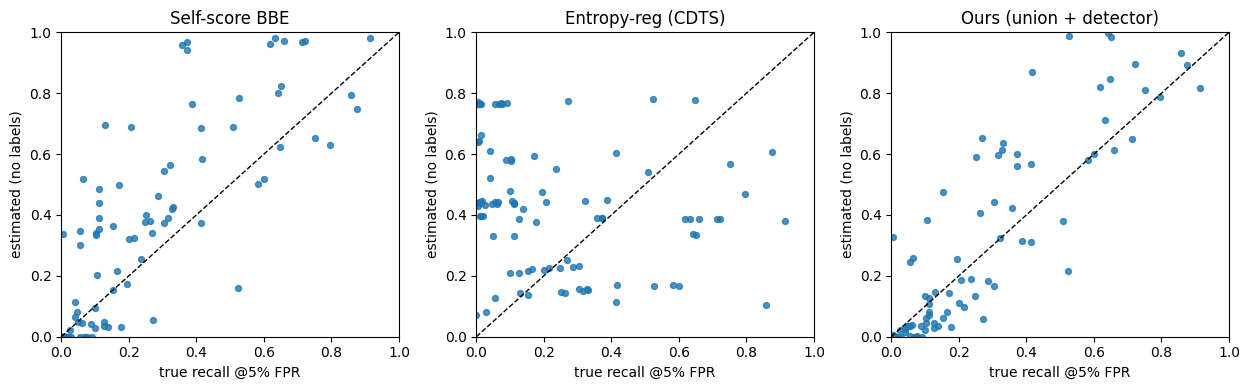

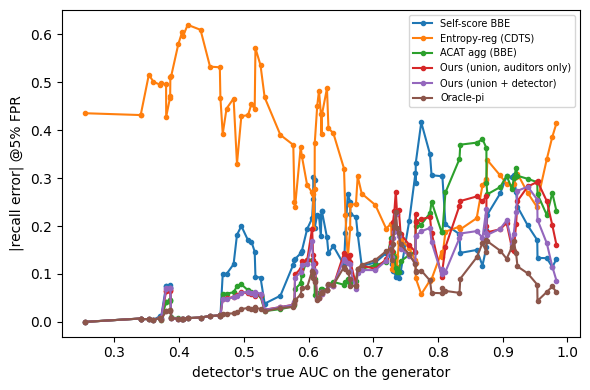

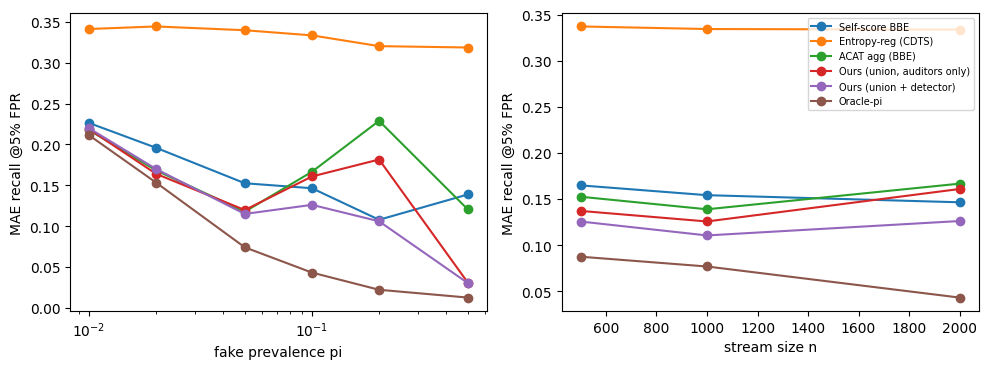

In [19]:
SHOW = ['Self-score BBE', 'Entropy-reg (CDTS)', 'ACAT agg (BBE)', OURS_AUD, OURS, 'Oracle-pi']

def fig_teaser(df):
    sub = df[(df.pi == CFG['MAIN_PI']) & (df.metric == 'tpr5')]
    sub = sub[sub.n == sub.groupby('stream_domain').n.transform('max')]
    g = sub.groupby(['stream_domain', 'detector', 'gen', 'method'])[['est', 'true']].mean().reset_index()
    ms = ['Self-score BBE', 'Entropy-reg (CDTS)', OURS]
    fig, ax = plt.subplots(1, len(ms), figsize=(4.2 * len(ms), 4))
    for a, m in zip(ax, ms):
        q = g[g.method == m]; a.scatter(q.true, q.est, s=18, alpha=.8)
        a.plot([0, 1], [0, 1], 'k--', lw=1); a.set_xlim(0, 1); a.set_ylim(0, 1)
        a.set_title(m); a.set_xlabel('true recall @5% FPR'); a.set_ylabel('estimated (no labels)')
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'fig1_teaser_est_vs_true.png'), dpi=200); plt.show()

def fig_err_vs_competence(df):
    sub = df[(df.pi == CFG['MAIN_PI']) & (df.metric == 'tpr5')]
    sub = sub[sub.n == sub.groupby('stream_domain').n.transform('max')]
    auc_true = (df[(df.method == 'Oracle-pi') & (df.metric == 'auc')].groupby(['stream_domain', 'detector', 'gen']).true.mean())
    g = sub.groupby(['stream_domain', 'detector', 'gen', 'method']).abs_err.mean().reset_index()
    g['det_auc'] = [auc_true.get((a, b, c), np.nan) for a, b, c in zip(g.stream_domain, g.detector, g.gen)]
    plt.figure(figsize=(6, 4))
    for m in SHOW:
        q = g[g.method == m].sort_values('det_auc')
        if len(q): plt.plot(q.det_auc, q.abs_err.rolling(5, min_periods=1).mean(), marker='o', ms=3, label=m)
    plt.xlabel("detector's true AUC on the generator"); plt.ylabel('|recall error| @5% FPR'); plt.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'fig2_err_vs_detector_auc.png'), dpi=200); plt.show()

def fig_err_vs_pi_n(df):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for m in SHOW:
        q = df[(df.method == m) & (df.metric == 'tpr5')]
        a = q[q.n == q.n.max()].groupby('pi').abs_err.mean(); ax[0].plot(a.index, a.values, marker='o', label=m)
        b = q[q.pi == CFG['MAIN_PI']].groupby('n').abs_err.mean(); ax[1].plot(b.index, b.values, marker='o', label=m)
    ax[0].set_xscale('log'); ax[0].set_xlabel('fake prevalence pi'); ax[1].set_xlabel('stream size n')
    for a in ax: a.set_ylabel('MAE recall @5% FPR')
    ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(os.path.join(FIG, 'fig3_err_vs_pi_and_n.png'), dpi=200); plt.show()
    t = (df[df.metric == 'pi'].groupby(['method', 'pi']).abs_err.mean().unstack('pi'))
    t.reindex([m for m in ORDER if m in t.index]).to_csv(os.path.join(RES, 'table_prevalence_err_by_pi.csv'))

fig_teaser(TRIALS); fig_err_vs_competence(TRIALS); fig_err_vs_pi_n(TRIALS)

## 14. Uncertainty: bootstrap intervals, coverage and abstention

                        covered                width              
metric                      auc     pi   tpr5    auc     pi   tpr5
method                                                            
Ours (union + detector)   0.885  0.812  0.854  0.459  0.104  0.327
Self-score BBE            0.839  0.594  0.874  0.577  0.093  0.423


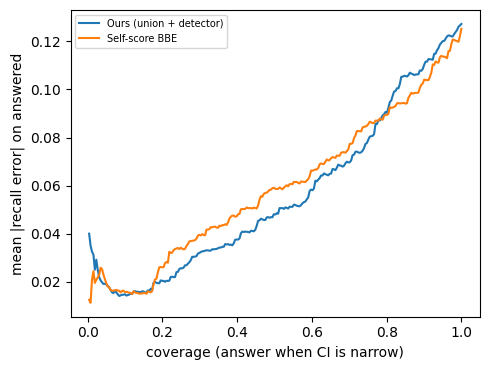

In [20]:
def boot_ci(idx, ref_domain, det, rng, which):
    ctx = CTX[(ref_domain, det)]; P = PVALS[ref_domain]
    cal3 = np.where(mask(domain=ref_domain, role='cal3', label=0, variant='clean'))[0]
    cal3 = cal3[np.isfinite(DET[det][cal3])]
    cands = {a: P[a] for a in DIR_AUD}; cands['detector'] = -DET[det]
    B = CFG['BOOT_B']; vals = []
    for _ in range(B):
        bi = rng.choice(idx, len(idx), replace=True); bc = rng.choice(cal3, len(cal3), replace=True)
        cb = dict(ctx); Rb = np.sort(DET[det][bc]); cb['R'] = Rb
        cb['f1'], cb['f5'], cb['f05'] = (float(np.mean(Rb > ctx[t])) for t in ('t1', 't5', 't05'))
        st = stream_stats(DET[det][bi], cb)
        pi_hat = union_estimate(CHOSEN['kind'], cands, bc, bi, rng, lcb_B=8) if which == 'ours' else bbe(-Rb, -DET[det][bi])[0]
        e = jain(pi_hat, st, cb); vals.append([e['pi'], e['tpr5'], e['auc']])
    a = (1 - CFG['CI_LEVEL']) / 2
    return np.quantile(np.array(vals), [a, 1 - a], axis=0)

def ci_experiment():
    f = os.path.join(RES, f'trials_ci_{stable_seed(sorted(DET), sorted(AUD_METHODS), CHOSEN["kind"], CFG["POOL_GENIMAGE_REALS"], "v5"):08x}.parquet')
    if os.path.exists(f): return pd.read_parquet(f)
    recs = []
    for dom in PVALS:
        rpool, fpools = pools(dom); n = max(nn for nn in CFG['NS'] if nn <= CFG['MAIN_N'])
        for det in DET:
            if (dom, det) not in CTX: continue
            ctx = CTX[(dom, det)]
            for g in eval_gens(det, dom, list(fpools)):
                for pi in (0.05, 0.1, 0.2):
                    for seed in range(CFG['BOOT_SEEDS']):
                        rng = np.random.default_rng(stable_seed('ci', dom, det, g, pi, seed))
                        smp = sample_stream(rpool, fpools[g], pi, n, rng)
                        if smp is None: continue
                        idx, y = smp; s = DET[det][idx]
                        if not np.isfinite(s).all(): continue
                        tr = truths(s, y, ctx, float(y.mean()))
                        est, _ = estimate_all(idx, y, dom, det, rng, methods=[OURS, 'Self-score BBE'])
                        for which, mname in (('ours', OURS), ('self', 'Self-score BBE')):
                            lo, hi = boot_ci(idx, dom, det, rng, which)
                            for j, mt in enumerate(('pi', 'tpr5', 'auc')):
                                recs.append((dom, det, g, pi, n, seed, mname, mt, est[mname][mt], tr[mt], lo[j], hi[j]))
    df = pd.DataFrame(recs, columns=['domain', 'detector', 'gen', 'pi', 'n', 'seed', 'method', 'metric', 'est', 'true', 'lo', 'hi'])
    df['covered'] = (df.true >= df.lo) & (df.true <= df.hi); df['width'] = df.hi - df.lo
    df.to_parquet(f); return df

CI = ci_experiment()
cov = CI.groupby(['method', 'metric'])[['covered', 'width']].mean().unstack('metric')
cov.to_csv(os.path.join(RES, 'table_ci_coverage.csv')); print(cov.round(3).to_string())

q = CI[(CI.metric == 'tpr5')].copy(); q['err'] = (q.est - q.true).abs()
plt.figure(figsize=(5, 3.8))
for m, g in q.groupby('method'):
    g = g.sort_values('width'); cov_ = np.arange(1, len(g) + 1) / len(g)
    plt.plot(cov_, g.err.expanding().mean(), label=m)
plt.xlabel('coverage (answer when CI is narrow)'); plt.ylabel('mean |recall error| on answered'); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, 'fig4_risk_coverage.png'), dpi=200); plt.show()

## 15. Ablations: auditor members and estimator (from the main trials)

In [21]:
abl_methods = METHOD_GROUPS['independent auditors (ablations)'] + METHOD_GROUPS['ours'] + ['Self-score BBE']
_ab = TRIALS[TRIALS.method.isin(abl_methods) & np.isclose(TRIALS.pi, CFG['MAIN_PI'])]
_ab = _ab[_ab.n == _ab.stream_domain.map({d: main_n_for(TRIALS, d) for d in TRIALS.stream_domain.unique()})]
abl = _ab.groupby(['stream_domain', 'method', 'metric']).abs_err.mean().unstack('metric').reindex(columns=['pi', 'tpr5', 'auc'])
abl = abl.reindex([(d, m) for d in abl.index.levels[0] for m in abl_methods if (d, m) in abl.index])
abl.to_csv(os.path.join(RES, 'table_ablation_auditors.csv')); print(abl.round(3).to_string())

def ref_size_ablation(fracs=(0.1, 0.25, 0.5, 1.0)):
    """Union (auditors only) with a subsampled real reference set: how many reference reals are needed?"""
    recs = []
    for dom in PVALS:
        base = dict(domain=dom, variant='clean')
        ref_all = np.where(mask(role='ref', **base))[0]; c1 = mask(role='cal1', **base)
        cal_idx = np.where(mask(role='cal3', label=0, **base))[0]
        dets = [d for d in DET if (dom, d) in CTX]
        if not dets: print(f'[{dom}] no detector context -> skipped'); continue
        rpool, fpools = pools(dom); det = dets[0]; ctx = CTX[(dom, det)]
        for fr in fracs:
            ref = np.random.default_rng(0).choice(ref_all, max(CFG['KNN_K'] + 1, int(fr * len(ref_all))), replace=False)
            Pd = directional_pvalues(raw_auditor_stats(ref), c1)
            for g in eval_gens(det, dom, list(fpools)):
                for seed in range(CFG['SEEDS']):
                    rng = np.random.default_rng(seed)
                    smp = sample_stream(rpool, fpools[g], CFG['MAIN_PI'], main_n_for(TRIALS, dom), rng)
                    if smp is None: continue
                    idx, y = smp; s_ = DET[det][idx]; st = stream_stats(s_, ctx)
                    e = jain(union_mpe(Pd, cal_idx, idx, rng)[0], st, ctx); tr = truths(s_, y, ctx, float(y.mean()))
                    recs.append((dom, fr, len(ref), abs(e['pi'] - tr['pi']), abs(e['tpr5'] - tr['tpr5'])))
    if not recs: return pd.DataFrame()
    t = pd.DataFrame(recs, columns=['domain', 'ref_frac', 'n_ref', 'abs_err_pi', 'abs_err_tpr5']).groupby(['domain', 'ref_frac', 'n_ref']).mean()
    t.to_csv(os.path.join(RES, 'table_ablation_reference_size.csv')); return t
print(ref_size_ablation().round(4).to_string())

metric                                        pi   tpr5    auc
stream_domain method                                          
chameleon     ACAT agg (BBE)               0.066  0.141  0.240
              Aud CLIP (both tails)        0.062  0.157  0.230
              Aud DINOv2 (both tails)      0.096  0.278  0.330
              Aud VAE (both tails)         0.100  0.336  0.339
              Aud Freq (both tails)        0.096  0.291  0.332
              Union, upper tails only      0.061  0.146  0.225
              Union Storey (auditors)      0.058  0.115  0.228
              Ours (union, auditors only)  0.061  0.150  0.232
              Ours (union + detector)      0.057  0.137  0.214
              Self-score BBE               0.062  0.094  0.237
genimage      ACAT agg (BBE)               0.066  0.167  0.182
              Aud CLIP (both tails)        0.087  0.277  0.255
              Aud DINOv2 (both tails)      0.068  0.185  0.182
              Aud VAE (both tails)         0.094  0.331

## 16. Proposition check: predicted vs observed bias, and auditor-detector coupling

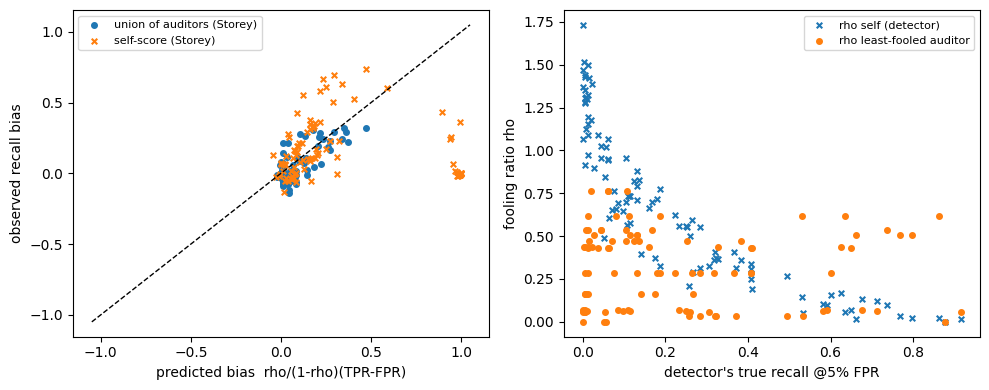

              true_tpr5  rho_self  rho_auditors  rho_union
true_tpr5         1.000    -0.948        -0.022     -0.341
rho_self         -0.948     1.000         0.082      0.421
rho_auditors     -0.022     0.082         1.000      0.770
rho_union        -0.341     0.421         0.770      1.000
least-fooled auditor counts: {'clip_hi': 49, 'hf_hi': 14, 'lap_lo': 11, 'vae_lo': 7, 'dino_hi': 7, 'lap_hi': 7, 'clip_lo': 4}
auditor                       clip   dino     hf    lap  union    vae
domain      detector                                                 
genimage    CLIP-LP@BigGAN   0.200 -1.000  0.400 -0.200 -0.400 -0.200
            CLIP-LP@SD15     1.000  0.800  0.200  0.200  0.400  0.200
            DINO-LP@BigGAN   0.200 -1.000  0.400 -0.200 -0.400 -0.200
            DINO-LP@SD15     0.800  0.600  0.400  0.400  0.800  0.400
            ResNet50@BigGAN -0.738 -0.316  0.949  0.738  0.211  0.738
            ResNet50@SD15    0.800  0.600  0.400  0.400  0.800  0.400
            UnivFD 

In [22]:
def fooling_ratios(P, cal3, fk):
    """rho_a = fake mass / real mass in each directional auditor's top half (lambda = median real p-value)."""
    out = {}
    for a in DIR_AUD:
        lam = np.quantile(P[a][cal3], 0.5); qr = np.mean(P[a][cal3] >= lam)
        out[a] = np.mean(P[a][fk] >= lam) / max(qr, 1e-12)
    return out

def theory_check():
    recs = []
    for dom in PVALS:
        P = PVALS[dom]; rpool, fpools = pools(dom)
        cal3 = mask(domain=dom, role='cal3', label=0, variant='clean')
        for det in DET:
            if (dom, det) not in CTX: continue
            ctx = CTX[(dom, det)]; med = np.quantile(-ctx['R'], 0.5)
            for g in eval_gens(det, dom, list(fpools)):
                fk = fpools[g]; sf = DET[det][fk]
                T = float(np.mean(sf > ctx['t5'])); Fp = ctx['f5']
                rhos = fooling_ratios(P, cal3, fk); best = min(rhos, key=rhos.get)
                rho_aud = rhos[best]
                rho_self = np.mean(-sf >= med) / 0.5
                pred = lambda rho: float(np.clip(rho / (1 - rho) * (T - Fp), -T, 1 - T)) if rho < 1 else 1 - T  # estimates are clipped to [0,1]
                obs = TRIALS[(TRIALS.stream_domain == dom) & (TRIALS.detector == det) & (TRIALS.gen == g) &
                             (TRIALS.metric == 'tpr5') & (TRIALS.n == main_n_for(TRIALS, dom)) & (TRIALS.pi >= 0.1)]
                o_aud = obs[obs.method == 'Union Storey (auditors)'].signed_err.mean()
                o_self = obs[obs.method == 'Self-score Storey'].signed_err.mean()
                recs.append((dom, det, g, T, best, rho_aud, rho_self, min(rho_aud, rho_self),
                             pred(rho_aud), o_aud, pred(rho_self), o_self))
    df = pd.DataFrame(recs, columns=['domain', 'detector', 'gen', 'true_tpr5', 'least_fooled_auditor', 'rho_auditors', 'rho_self',
                                     'rho_union', 'pred_bias_auditors', 'obs_bias_auditors', 'pred_bias_self', 'obs_bias_self'])
    df.to_csv(os.path.join(RES, 'table_theory_check.csv'), index=False)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].scatter(df.pred_bias_auditors, df.obs_bias_auditors, label='union of auditors (Storey)', s=16)
    ax[0].scatter(df.pred_bias_self, df.obs_bias_self, label='self-score (Storey)', s=16, marker='x')
    lim = np.nanmax(np.abs(df[['pred_bias_auditors', 'obs_bias_auditors', 'pred_bias_self', 'obs_bias_self']].values)) * 1.05
    ax[0].plot([-lim, lim], [-lim, lim], 'k--', lw=1); ax[0].set_xlabel('predicted bias  rho/(1-rho)(TPR-FPR)')
    ax[0].set_ylabel('observed recall bias'); ax[0].legend(fontsize=8)
    ax[1].scatter(df.true_tpr5, df.rho_self, label='rho self (detector)', s=16, marker='x')
    ax[1].scatter(df.true_tpr5, df.rho_auditors, label='rho least-fooled auditor', s=16)
    ax[1].set_xlabel("detector's true recall @5% FPR"); ax[1].set_ylabel('fooling ratio rho'); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(FIG, 'fig5_theory_and_coupling.png'), dpi=200); plt.show()
    print(df[['true_tpr5', 'rho_self', 'rho_auditors', 'rho_union']].corr(method='spearman').round(3))
    print('least-fooled auditor counts:', df.least_fooled_auditor.value_counts().to_dict())
    return df
THEORY = theory_check()

# auditor-detector coupling: does an auditor get fooled by the same generators as the detector? (spearman recall vs rho)
def coupling_table():
    recs = []
    for dom in PVALS:
        P = PVALS[dom]; rpool, fpools = pools(dom); cal3 = mask(domain=dom, role='cal3', label=0, variant='clean')
        for det in DET:
            if (dom, det) not in CTX: continue
            ctx = CTX[(dom, det)]; gs = eval_gens(det, dom, list(fpools))
            if len(gs) < 3: continue
            T = [np.mean(DET[det][fpools[g]] > ctx['t5']) for g in gs]
            R = [fooling_ratios(P, cal3, fpools[g]) for g in gs]
            for b in BASE_AUD:
                recs.append((dom, det, b, stats.spearmanr(T, [min(r[f'{b}_hi'], r[f'{b}_lo']) for r in R]).correlation))
            recs.append((dom, det, 'union', stats.spearmanr(T, [min(r.values()) for r in R]).correlation))
    t = pd.DataFrame(recs, columns=['domain', 'detector', 'auditor', 'spearman(recall, rho)']).pivot_table(
        index=['domain', 'detector'], columns='auditor', values='spearman(recall, rho)')
    t.to_csv(os.path.join(RES, 'table_auditor_detector_coupling.csv')); return t
print(coupling_table().round(3).to_string())

## 17. Mixed-generator streams

In [23]:
def mixed_experiment(k=3, seeds=20):
    recs = []
    for dom in PVALS:
        rpool, fpools = pools(dom)
        for det in DET:
            if (dom, det) not in CTX: continue
            ctx = CTX[(dom, det)]; gs = eval_gens(det, dom, list(fpools))
            if len(gs) < k: continue
            for seed in range(seeds):
                rng = np.random.default_rng(seed); pick = list(rng.choice(gs, k, replace=False))
                smp = sample_stream(rpool, {g: fpools[g] for g in pick}, CFG['MAIN_PI'], main_n_for(TRIALS, dom), rng)
                if smp is None: continue
                idx, y = smp; s = DET[det][idx]
                if not np.isfinite(s).all(): continue
                tr = truths(s, y, ctx, float(y.mean())); est, _ = estimate_all(idx, y, dom, det, rng)
                for m, e in est.items():
                    for mt in ('pi', 'tpr5', 'auc', 'acc'): recs.append((dom, det, seed, m, mt, abs(e[mt] - tr[mt])))
    df = pd.DataFrame(recs, columns=['domain', 'detector', 'seed', 'method', 'metric', 'abs_err'])
    if not len(df): return df
    t = df.groupby(['domain', 'method', 'metric']).abs_err.mean().unstack('metric')
    t = t.reindex([(d, m) for d in t.index.levels[0] for m in ORDER if (d, m) in t.index])
    t.to_csv(os.path.join(RES, 'table_mixed_streams.csv')); return t
print(mixed_experiment().round(3).to_string())

metric                                     acc    auc     pi   tpr5
domain      method                                                 
genimage    AC                           0.055    NaN    NaN    NaN
            ATC                          0.054    NaN    NaN    NaN
            DoC                          0.054    NaN    NaN    NaN
            Entropy-reg (CDTS)           0.041  0.161    NaN  0.260
            MaNo-reg                     0.040  0.161    NaN  0.261
            Self-score Storey            0.052  0.210  0.062  0.268
            Self-score BBE               0.049  0.175  0.056  0.213
            ACAT agg (BBE)               0.053  0.202  0.069  0.371
            Aud CLIP (both tails)        0.067  0.288  0.092  0.516
            Aud DINOv2 (both tails)      0.056  0.216  0.070  0.357
            Aud VAE (both tails)         0.069  0.307  0.099  0.548
            Aud Freq (both tails)        0.066  0.273  0.090  0.505
            Union, upper tails only      0.056  

## 18. Robustness to real-side shift + the uniformity guard
Guard: if real images are stable, stream p-values above 0.2 follow the same distribution as held-out real p-values (fakes sit mostly below 0.2). A two-sample KS test that rejects at 1% flags a real-side shift and the estimate abstains.
Two shifts: (a) synthetic JPEG70 + 2x resampling of the whole stream; (b) cross-domain (GenImage reference, Synthbuster stream).

In [24]:
def guard_flag(p, p_real, lo=0.2, alpha=0.01):
    """Two-sample KS: stream p-values above `lo` vs held-out real (cal3) p-values above `lo`.
    Fakes sit mostly below `lo`, so a mismatch above `lo` signals a shift of the REAL distribution."""
    x, r = p[p > lo], p_real[p_real > lo]
    if len(x) < 30 or len(r) < 30: return True
    return stats.ks_2samp(x, r).pvalue < alpha

def shift_experiment():
    settings = []
    if CFG['RUN_SHIFT'] and train_dom in PVALS: settings += [('clean', train_dom, train_dom, 'clean'), ('JPEG70+resample', train_dom, train_dom, 'shift')]
    if train_dom in PVALS:
        for d in DOMAINS:
            if d != train_dom: settings.append((f'cross-domain ({train_dom} ref -> {d})', d, train_dom, 'clean'))
    recs = []
    for name, sdom, rdom, var in settings:
        rpool, fpools = pools(sdom, var)
        for det in DET:
            if (rdom, det) not in CTX: continue
            ctx = CTX[(rdom, det)]
            for g in eval_gens(det, sdom, list(fpools)):
                for pi in (0.05, 0.1, 0.2):
                    n = min(1000, len(rpool) + 1)
                    for seed in range(CFG['SEEDS']):
                        rng = np.random.default_rng(seed)
                        smp = sample_stream(rpool, fpools[g], pi, n, rng)
                        if smp is None: continue
                        idx, y = smp; s = DET[det][idx]
                        if not np.isfinite(s).all(): continue
                        tr = truths(s, y, ctx, float(y.mean()))
                        est, _ = estimate_all(idx, y, rdom, det, rng, methods=[OURS, 'Self-score BBE', 'Oracle-pi'])
                        flag = guard_flag(PVALS[rdom]['acat'][idx], PVALS[rdom]['acat'][CAL3[rdom]])
                        for m, e in est.items():
                            recs.append((name, det, g, pi, seed, m, flag, abs(e['pi'] - tr['pi']), abs(e['tpr5'] - tr['tpr5'])))
    df = pd.DataFrame(recs, columns=['setting', 'detector', 'gen', 'pi', 'seed', 'method', 'guard_flag', 'err_pi', 'err_tpr5'])
    if not len(df): print('no shift settings available'); return df
    t = df.groupby(['setting', 'method']).agg(MAE_pi=('err_pi', 'mean'), MAE_tpr5=('err_tpr5', 'mean'), guard_rate=('guard_flag', 'mean'))
    t2 = (df[~df.guard_flag].groupby(['setting', 'method']).agg(MAE_tpr5_after_guard=('err_tpr5', 'mean')))
    t = t.join(t2); t.to_csv(os.path.join(RES, 'table_shift_and_guard.csv')); print(t.round(3).to_string())
    return df
SHIFT = shift_experiment()

                                                                    MAE_pi  MAE_tpr5  guard_rate  MAE_tpr5_after_guard
setting                                    method                                                                     
JPEG70+resample                            Oracle-pi                 0.000     0.201       1.000                   NaN
                                           Ours (union + detector)   0.878     0.129       1.000                   NaN
                                           Self-score BBE            0.460     0.112       1.000                   NaN
clean                                      Oracle-pi                 0.000     0.056       0.069                 0.059
                                           Ours (union + detector)   0.055     0.128       0.069                 0.135
                                           Self-score BBE            0.069     0.146       0.069                 0.146
cross-domain (genimage ref -> chameleon)   Oracl

## 19. Use cases: detector selection and recall alarms

In [25]:
def usecases(df):
    sub = df[(df.pi == CFG['MAIN_PI']) & (df.metric == 'auc')]
    sub = sub[sub.n == sub.groupby('stream_domain').n.transform('max')]
    sel = []
    for (dom, g, seed, m), q in sub.groupby(['stream_domain', 'gen', 'seed', 'method']):
        q = q.dropna(subset=['est'])
        if q.detector.nunique() >= 3:
            sel.append((dom, m, stats.spearmanr(q.est, q.true).correlation,
                        float(q.loc[q.est.idxmax(), 'true'] == q.true.max())))
    sel = pd.DataFrame(sel, columns=['domain', 'method', 'spearman', 'top1']).groupby(['domain', 'method']).mean()
    al = []
    sub = df[(df.pi == CFG['MAIN_PI']) & (df.metric == 'tpr5')]
    sub = sub[sub.n == sub.groupby('stream_domain').n.transform('max')]
    for (dom, m), q in sub.groupby(['stream_domain', 'method']):
        q = q.dropna(subset=['est']); lab = (q.true < 0.5).astype(int)
        if 0 < lab.sum() < len(lab): al.append((dom, m, roc_auc_score(lab, -q.est)))
    al = pd.DataFrame(al, columns=['domain', 'method', 'alarm AUROC (recall<0.5)']).set_index(['domain', 'method'])
    t = sel.join(al, how='outer'); t.to_csv(os.path.join(RES, 'table_usecases.csv')); return t
print(usecases(TRIALS).round(3).to_string())

                                         spearman   top1  alarm AUROC (recall<0.5)
domain      method                                                                
chameleon   ACAT agg (BBE)                  0.897  0.100                       NaN
            Aud CLIP (both tails)           0.907  0.500                       NaN
            Aud DINOv2 (both tails)         0.890  0.000                       NaN
            Aud Freq (both tails)           0.884  0.000                       NaN
            Aud VAE (both tails)            0.872  0.000                       NaN
            Entropy-reg (CDTS)             -0.021  0.000                       NaN
            Labelled audit (100)            0.921  0.400                       NaN
            MaNo-reg                        0.086  0.000                       NaN
            Oracle-pi                       0.871  0.800                       NaN
            Ours (union + detector)         0.923  0.700                       NaN
    

## 20. Summary of produced files

In [26]:
for f in sorted(glob.glob(os.path.join(RES, '**', '*'), recursive=True)):
    if os.path.isfile(f): print(f'{os.path.getsize(f) / 1e3:8.1f} KB  {f}')
json.dump({k: (v if not isinstance(v, np.ndarray) else v.tolist()) for k, v in CFG.items()},
          open(os.path.join(RES, 'config_used.json'), 'w'), indent=1)
print('Detectors:', {k: DET_META[k] for k in DET})

   139.6 KB  /kaggle/working/results/figures/fig1_teaser_est_vs_true.png
   181.1 KB  /kaggle/working/results/figures/fig2_err_vs_detector_auc.png
   166.0 KB  /kaggle/working/results/figures/fig3_err_vs_pi_and_n.png
    77.7 KB  /kaggle/working/results/figures/fig4_risk_coverage.png
   141.2 KB  /kaggle/working/results/figures/fig5_theory_and_coupling.png
    21.2 KB  /kaggle/working/results/figures/pilot_pvalue_hist.png
     6.7 KB  /kaggle/working/results/pilot_auc_auditors_vs_detectors.csv
     2.8 KB  /kaggle/working/results/table_ablation_auditors.csv
     0.7 KB  /kaggle/working/results/table_ablation_reference_size.csv
     1.9 KB  /kaggle/working/results/table_auditor_detector_coupling.csv
     1.1 KB  /kaggle/working/results/table_by_competence_pi0.1.csv
     1.1 KB  /kaggle/working/results/table_by_competence_pi0.2.csv
     0.4 KB  /kaggle/working/results/table_ci_coverage.csv
     0.6 KB  /kaggle/working/results/table_detectors.csv
     0.3 KB  /kaggle/working/results/table